# Biomedical Disease Named Entity Recognition
**COMP9444 project 013** · BioBERT on the NCBI Disease Corpus

We compare three scopes of supervised fine-tuning and three variants of task-adaptive masked language modeling. The notebook includes the implementation, a complete results snapshot, and an optional replay of all runs.

**Author Tian Huang**

## 1. Introduction

The task is to recover disease mentions from PubMed titles and abstracts as exact character spans with one of four mention types. We ask how the number of trainable layers affects performance and cost, and whether continued pretraining on the task's training text improves downstream NER. The experiments compare held-out documents within the NCBI corpus.

[NCBI Disease Corpus](https://pubmed.ncbi.nlm.nih.gov/24393765/) · [BioBERT](https://doi.org/10.1093/bioinformatics/btz682) · [Task-adaptive pretraining](https://aclanthology.org/2020.acl-main.740/)

### Reproducible environment

Run the notebook from top to bottom to regenerate preprocessing, evaluation tables and plots. The recorded study results are included in this file. Set **REPLAY_STUDY = True** in Section 6 to repeat the three-seed experiment. A CUDA GPU is recommended. A fresh replay needs internet access to fetch the NCBI archives and the pinned model and tokenizer. In the local project environment, set **HF_HUB_CACHE** to the downloaded cache before starting Jupyter.

In [1]:
# Install missing dependencies in this kernel; no repository files are required.
import importlib.util
import importlib.metadata
import subprocess
import sys

required_packages = {
    "torch": "torch==2.9.0",
    "transformers": "transformers==5.3.0",
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
}
missing_packages = [package for module, package in required_packages.items()
                    if importlib.util.find_spec(module) is None
                    or (module == "transformers" and importlib.metadata.version(module) != "5.3.0")]
if missing_packages:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing_packages])
print("Python:", sys.version.split()[0])
for package in required_packages:
    print(f"{package}: {importlib.metadata.version(package)}")

Python: 3.13.2
torch: 2.12.0+cu130
transformers: 5.3.0
numpy: 2.2.6
pandas: 2.3.2
matplotlib: 3.10.5


In [2]:
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile
import shutil

import numpy as np
import pandas as pd
import torch

print("CUDA available:", torch.cuda.is_available())

CUDA available: True


## 2. Data loading

The corpus supplies 593 training, 100 development and 100 test records. The loader retains the published splits. The MLM experiments deduplicate training records by PMID before creating a private training/validation split.

[Official corpus archives](https://www.ncbi.nlm.nih.gov/CBBresearch/Dogan/DISEASE/corpus.html)

In [3]:
# from one of its subdirectories.
notebook_name = "MedNLP_research.ipynb"
notebook_dir = next(
    (directory for directory in (Path.cwd(), *Path.cwd().parents)
     if (directory / notebook_name).is_file()),
    Path.cwd(),
)
raw_data_dir = notebook_dir / "Dataset" / "RawData"
raw_data_dir.mkdir(parents=True, exist_ok=True)

# download for data scource
datasets = {
    "training": {
        "url": "https://www.ncbi.nlm.nih.gov/CBBresearch/Dogan/DISEASE/NCBItrainset_corpus.zip",
        "source_name": "NCBItrainset_corpus.txt",
        "target_name": "NCBI_training.txt",
    },
    "validation": {
        "url": "https://www.ncbi.nlm.nih.gov/CBBresearch/Dogan/DISEASE/NCBIdevelopset_corpus.zip",
        "source_name": "NCBIdevelopset_corpus.txt",
        "target_name": "NCBI_validation.txt",
    },
    "testing": {
        "url": "https://www.ncbi.nlm.nih.gov/CBBresearch/Dogan/DISEASE/NCBItestset_corpus.zip",
        "source_name": "NCBItestset_corpus.txt",
        "target_name": "NCBI_testing.txt",
    },
}

for split, dataset_info in datasets.items():
    target_path = raw_data_dir / dataset_info["target_name"]

    if target_path.is_file():
        print(f"{split.capitalize()} set already exists: {target_path.name}")
        continue

    archive_path = raw_data_dir / Path(dataset_info["url"]).name
    partial_archive_path = archive_path.with_suffix(archive_path.suffix + ".part")
    partial_target_path = target_path.with_suffix(target_path.suffix + ".part")

    print(f"Downloading {split} set...")
    urlretrieve(dataset_info["url"], partial_archive_path)
    partial_archive_path.replace(archive_path)

    # decompress the file
    try:
        with ZipFile(archive_path) as zip_file:
            source_member = next(
                member for member in zip_file.namelist()
                if Path(member).name == dataset_info["source_name"]
            )
            with zip_file.open(source_member) as source, partial_target_path.open("wb") as target:
                shutil.copyfileobj(source, target)
        partial_target_path.replace(target_path)
    finally:
        archive_path.unlink(missing_ok=True)
        partial_target_path.unlink(missing_ok=True)

    print(f"Saved {split} set to: {target_path.name}")

print("NCBI Disease Corpus download and extraction completed.")

Training set already exists: NCBI_training.txt
Validation set already exists: NCBI_validation.txt
Testing set already exists: NCBI_testing.txt
NCBI Disease Corpus download and extraction completed.


## 3. Data processing and analysis

The converter joins title and abstract with one space and preserves the corpus coordinate system. The source contains two training annotation ends inside a word. Both are extended to the word boundary for token alignment. The validation and test gold boundaries require zero corrections. The converter records one additional training mention-text mismatch while retaining its supplied offsets.

In [4]:
import json
from pathlib import Path

# Locate the dataset directories from the project root.
project_dir = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "Dataset" / "RawData").is_dir()),
    Path.cwd(),
)
raw_data_dir = project_dir / "Dataset" / "RawData"
processed_data_dir = project_dir / "Dataset" / "ProcessedData"
processed_data_dir.mkdir(parents=True, exist_ok=True)

source_files = (
    "NCBI_training.txt",
    "NCBI_validation.txt",
    "NCBI_testing.txt",
)


def convert_pubtator_to_jsonl(input_path, output_path):
    # Keep every source block, including repeated PMIDs.
    documents = []
    document = None

    with input_path.open(encoding="utf-8") as source:
        for raw_line in source:
            line = raw_line.rstrip("\r\n")
            if not line:
                if document is not None:
                    documents.append(document)
                    document = None
                continue

            if "|t|" in line or "|a|" in line:
                pmid, section, content = line.split("|", 2)
                if section == "t":
                    document = {"pmid": pmid, "title": content, "abstract": "", "entities": []}
                else:
                    document["abstract"] = content
            else:
                fields = line.split("\t")
                if len(fields) < 5:
                    raise ValueError(f"Invalid annotation line: {line}")
                pmid, start, end, mention, entity_type = fields[:5]
                document["entities"].append(
                    {
                        "start": int(start),
                        "end": int(end),
                        "mention": mention,
                        "type": entity_type,
                    }
                )

    if document is not None:
        documents.append(document)

    mismatch_count = 0
    boundary_correction_count = 0
    with output_path.open("w", encoding="utf-8") as destination:
        for document_index, document in enumerate(documents):
            # Corpus offsets use: title + one space + abstract.
            text = document["title"] + " " + document["abstract"]
            entities = []

            for entity in document["entities"]:
                start, end = entity["start"], entity["end"]
                if not 0 <= start < end <= len(text):
                    raise ValueError(
                        f"Invalid offset in PMID {document['pmid']}: [{start}, {end})"
                    )
                if text[start:end] != entity["mention"]:
                    mismatch_count += 1

                # Repair corpus annotations that end inside a word. Such
                # partial-word spans cannot align with WordPiece boundaries.
                original_end = end
                while (
                    end < len(text)
                    and text[end - 1].isalnum()
                    and text[end].isalnum()
                ):
                    end += 1
                boundary_correction_count += int(end != original_end)
                entities.append(
                    {"start": start, "end": end, "type": entity["type"]}
                )

            record = {
                "record_id": f"{input_path.stem}-{document_index:04d}",
                "pmid": document["pmid"],
                "title": document["title"],
                "abstract": document["abstract"],
                "text": text,
                "entities": entities,
            }
            destination.write(json.dumps(record, ensure_ascii=False) + "\n")

    return len(documents), mismatch_count, boundary_correction_count


for source_name in source_files:
    input_path = raw_data_dir / source_name
    output_path = processed_data_dir / Path(source_name).with_suffix(".jsonl").name
    (
        document_count,
        mismatch_count,
        boundary_correction_count,
    ) = convert_pubtator_to_jsonl(input_path, output_path)
    print(
        f"Saved {document_count} documents to: {output_path.name} "
        f"({mismatch_count} annotation text mismatch(es), "
        f"{boundary_correction_count} boundary correction(s))"
    )

Saved 593 documents to: NCBI_training.jsonl (1 annotation text mismatch(es), 2 boundary correction(s))
Saved 100 documents to: NCBI_validation.jsonl (0 annotation text mismatch(es), 0 boundary correction(s))
Saved 100 documents to: NCBI_testing.jsonl (0 annotation text mismatch(es), 0 boundary correction(s))


### 3.1 Training and validation document lengths

,Documents,Unique PMIDs,Repeated Records,Entity Mentions,Unique Entity Texts,Mean Document Length,Median Document Length,95th Percentile Length,Maximum Document Length
Split,,,,,,,,,
Training,593,592,1,5145,1690,1264.72,1276.0,1909.8,2656
Validation,100,100,0,787,363,1326.40,1272.0,1895.4,2193


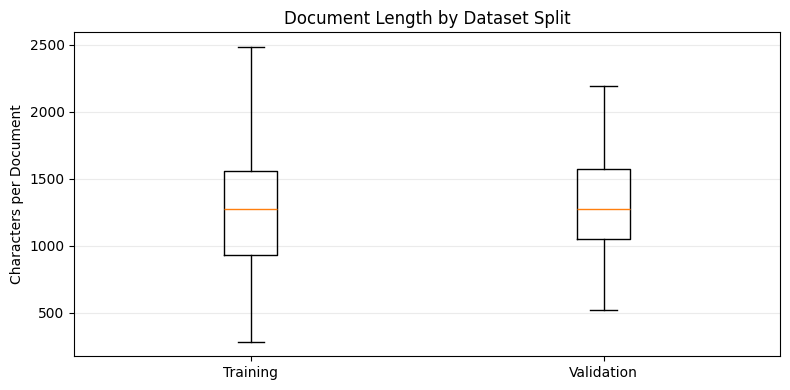

In [5]:
import matplotlib.pyplot as plt
from IPython.display import display

# Load only the training and validation splits for exploratory analysis.
# Keep the testing split untouched to avoid test-set-driven decisions.
split_files = {
    "Training": "NCBI_training.jsonl",
    "Validation": "NCBI_validation.jsonl",
}
records_by_split = {}

for split, file_name in split_files.items():
    file_path = processed_data_dir / file_name
    with file_path.open(encoding="utf-8") as source:
        records_by_split[split] = [json.loads(line) for line in source if line.strip()]

# Summarise dataset size and document character lengths.
scale_rows = []
for split, records in records_by_split.items():
    document_lengths = pd.Series([len(record["text"]) for record in records])
    entity_texts = [
        record["text"][entity["start"]:entity["end"]]
        for record in records
        for entity in record["entities"]
    ]
    unique_pmids = len({record["pmid"] for record in records})

    scale_rows.append({
        "Split": split,
        "Documents": len(records),
        "Unique PMIDs": unique_pmids,
        "Repeated Records": len(records) - unique_pmids,
        "Entity Mentions": len(entity_texts),
        "Unique Entity Texts": len(set(entity_texts)),
        "Mean Document Length": document_lengths.mean(),
        "Median Document Length": document_lengths.median(),
        "95th Percentile Length": document_lengths.quantile(0.95),
        "Maximum Document Length": document_lengths.max(),
    })

scale_summary = pd.DataFrame(scale_rows).set_index("Split")
display(scale_summary.round(2))

# Compare document-length distributions across splits.
plt.figure(figsize=(8, 4))
plt.boxplot(
    [[len(record["text"]) for record in records_by_split[split]] for split in split_files],
    tick_labels=list(split_files),
    showfliers=False,
)
plt.title("Document Length by Dataset Split")
plt.ylabel("Characters per Document")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### 3.2 实体分布

,Entities per Document,"Entities per 1,000 Characters",Zero-Entity Documents,Mean Entity Length,Median Entity Length,95th Percentile Entity Length,Maximum Entity Length,Single-Word Entities (%),Multi-Word Entities (%)
Split,,,,,,,,,
Training,8.68,6.86,0,15.19,14.0,37.0,80,46.69,53.31
Validation,7.87,5.93,0,15.74,15.0,37.0,74,42.69,57.31


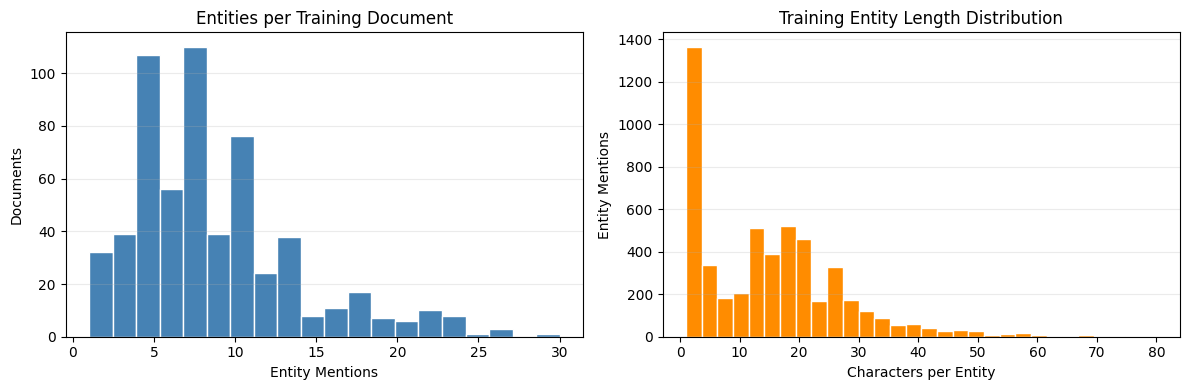

In [6]:
# Summarise entity density and character length for each split.
entity_rows = []
for split, records in records_by_split.items():
    entity_counts = pd.Series([len(record["entities"]) for record in records])
    entity_texts = [
        record["text"][entity["start"]:entity["end"]]
        for record in records
        for entity in record["entities"]
    ]
    entity_lengths = pd.Series([len(text) for text in entity_texts])
    total_characters = sum(len(record["text"]) for record in records)
    single_word_count = sum(len(text.split()) == 1 for text in entity_texts)

    entity_rows.append({
        "Split": split,
        "Entities per Document": entity_counts.mean(),
        "Entities per 1,000 Characters": len(entity_texts) / total_characters * 1000,
        "Zero-Entity Documents": int((entity_counts == 0).sum()),
        "Mean Entity Length": entity_lengths.mean(),
        "Median Entity Length": entity_lengths.median(),
        "95th Percentile Entity Length": entity_lengths.quantile(0.95),
        "Maximum Entity Length": entity_lengths.max(),
        "Single-Word Entities (%)": single_word_count / len(entity_texts) * 100,
        "Multi-Word Entities (%)": (len(entity_texts) - single_word_count) / len(entity_texts) * 100,
    })

entity_summary = pd.DataFrame(entity_rows).set_index("Split")
display(entity_summary.round(2))

# Plot the main entity distributions in the training set.
training_records = records_by_split["Training"]
training_entity_counts = [len(record["entities"]) for record in training_records]
training_entity_lengths = [
    entity["end"] - entity["start"]
    for record in training_records
    for entity in record["entities"]
]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(training_entity_counts, bins=20, color="steelblue", edgecolor="white")
axes[0].set_title("Entities per Training Document")
axes[0].set_xlabel("Entity Mentions")
axes[0].set_ylabel("Documents")

axes[1].hist(training_entity_lengths, bins=30, color="darkorange", edgecolor="white")
axes[1].set_title("Training Entity Length Distribution")
axes[1].set_xlabel("Characters per Entity")
axes[1].set_ylabel("Entity Mentions")

for axis in axes:
    axis.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

Number of entity types: 4
Entity types: CompositeMention, DiseaseClass, Modifier, SpecificDisease


Split,Training,Validation,Total,Total (%)
Entity Type,,,,
SpecificDisease,2972,412,3384,57.05
Modifier,1289,214,1503,25.34
DiseaseClass,769,126,895,15.09
CompositeMention,115,35,150,2.53


Split,Training (%),Validation (%)
Entity Type,,
CompositeMention,2.24,4.45
DiseaseClass,14.95,16.01
Modifier,25.05,27.19
SpecificDisease,57.76,52.35


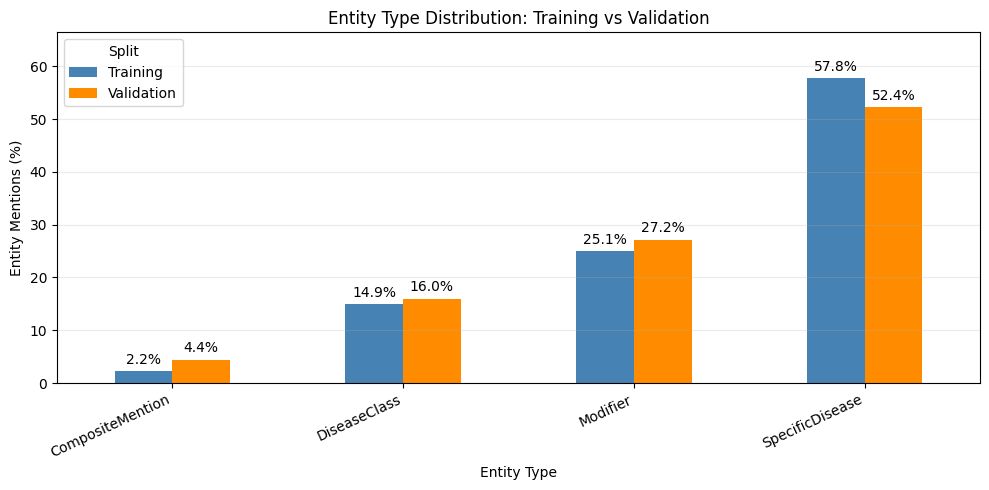

In [7]:
# Analyse entity mention types in the training and validation splits.
missing_type_records = [
    record["record_id"]
    for records in records_by_split.values()
    for record in records
    if any("type" not in entity for entity in record["entities"])
]
if missing_type_records:
    raise ValueError(
        "Entity type is missing from ProcessedData. "
        "Re-run Section 3.0 before this analysis."
    )

entity_types = sorted({
    entity["type"]
    for records in records_by_split.values()
    for record in records
    for entity in record["entities"]
})
print(f"Number of entity types: {len(entity_types)}")
print("Entity types:", ", ".join(entity_types))

type_distribution_rows = []
for split, records in records_by_split.items():
    split_types = [
        entity["type"]
        for record in records
        for entity in record["entities"]
    ]
    split_total = len(split_types)
    for entity_type in entity_types:
        count = split_types.count(entity_type)
        type_distribution_rows.append({
            "Split": split,
            "Entity Type": entity_type,
            "Count": count,
            "Percentage": count / split_total * 100,
        })

type_distribution = pd.DataFrame(type_distribution_rows)
type_count_summary = type_distribution.pivot(
    index="Entity Type", columns="Split", values="Count"
).reindex(columns=list(split_files)).astype(int)
type_count_summary["Total"] = type_count_summary.sum(axis=1)
type_count_summary["Total (%)"] = (
    type_count_summary["Total"]
    / type_count_summary["Total"].sum()
    * 100
)
display(type_count_summary.sort_values("Total", ascending=False).round(2))

type_percentage_summary = type_distribution.pivot(
    index="Entity Type", columns="Split", values="Percentage"
).reindex(columns=list(split_files))
display(type_percentage_summary.round(2).add_suffix(" (%)"))

# Compare within-split percentages so split size does not distort the chart.
plot_percentages = type_percentage_summary.loc[entity_types]
axis = plot_percentages.plot(
    kind="bar",
    figsize=(10, 5),
    color=["steelblue", "darkorange"],
)
for container in axis.containers:
    axis.bar_label(container, fmt="%.1f%%", padding=3)
plt.title("Entity Type Distribution: Training vs Validation")
plt.xlabel("Entity Type")
plt.ylabel("Entity Mentions (%)")
plt.xticks(rotation=25, ha="right")
plt.ylim(0, plot_percentages.to_numpy().max() * 1.15)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


### 3.3 BioBERT tokenization

Token offsets are relative to the full document. Only the training cache contains gold BIO labels.

In [8]:
from transformers.models.bert.tokenization_bert import BertTokenizerFast

BIOBERT_MODEL = "dmis-lab/biobert-base-cased-v1.1"
# BioBERT v1.1 inherits the BERT-base-cased WordPiece vocabulary.

BIOBERT_TOKENIZER = "google-bert/bert-base-cased"

ENTITY_TYPES = (
    "SpecificDisease",
    "DiseaseClass",
    "CompositeMention",
    "Modifier",
)
BIO_LABELS = ["O"]
for entity_type in ENTITY_TYPES:
    BIO_LABELS.extend([
        f"B-{entity_type}",
        f"I-{entity_type}",
    ])
LABEL2ID = {
    label: label_id for label_id, label in enumerate(BIO_LABELS)
}
ID2LABEL = {
    label_id: label for label, label_id in LABEL2ID.items()
}

dataset_files = (
    "NCBI_training.jsonl",
    "NCBI_validation.jsonl",
    "NCBI_testing.jsonl",
)

biobert_output_dir = (
    project_dir / "Dataset" / "TokenizedData" / "BioBERT"
)
biobert_output_dir.mkdir(parents=True, exist_ok=True)

tokenized_training_path = (
    biobert_output_dir / "NCBI_training.jsonl"
)


def create_typed_bio_tags(offsets, entities, record_id):
    """Align character-level entities with BioBERT WordPieces."""
    bio_tags = ["O"] * len(offsets)

    for entity in sorted(
        entities, key=lambda item: (item["start"], item["end"])
    ):
        required_fields = {"start", "end", "type"}
        if not required_fields.issubset(entity):
            raise ValueError(
                f"Incomplete entity annotation in {record_id}: {entity}"
            )

        entity_start = entity["start"]
        entity_end = entity["end"]
        entity_type = entity["type"]
        if entity_type not in ENTITY_TYPES:
            raise ValueError(
                f"Unknown entity type {entity_type!r} in {record_id}"
            )

        token_indices = [
            token_index
            for token_index, (token_start, token_end) in enumerate(offsets)
            if token_start < entity_end and token_end > entity_start
        ]
        if not token_indices:
            raise ValueError(
                f"Entity [{entity_start}, {entity_end}) has no token "
                f"alignment in {record_id}"
            )

        first_token = token_indices[0]
        last_token = token_indices[-1]
        if (
            offsets[first_token][0] != entity_start
            or offsets[last_token][1] != entity_end
        ):
            raise ValueError(
                f"Entity boundary [{entity_start}, {entity_end}) is not "
                f"aligned with token boundaries in {record_id}"
            )

        if any(bio_tags[index] != "O" for index in token_indices):
            raise ValueError(
                f"Overlapping entities are not supported in {record_id}"
            )

        bio_tags[first_token] = f"B-{entity_type}"
        for token_index in token_indices[1:]:
            bio_tags[token_index] = f"I-{entity_type}"

    return bio_tags


def tokenize_dataset(
    input_path,
    output_path,
    tokenizer,
    model_name,
    tokenizer_name,
    include_gold_labels,
):
    document_count = 0
    token_count = 0

    with input_path.open(encoding="utf-8") as source:
        with output_path.open("w", encoding="utf-8") as destination:
            for line in source:
                if not line.strip():
                    continue

                record = json.loads(line)
                encoded = tokenizer(
                    record["text"],
                    add_special_tokens=False,
                    truncation=False,
                    return_attention_mask=True,
                    verbose=False,
                    return_offsets_mapping=True,
                )
                tokens = tokenizer.convert_ids_to_tokens(
                    encoded["input_ids"]
                )
                offsets = [
                    [start, end]
                    for start, end in encoded["offset_mapping"]
                ]

                has_invalid_offset = any(
                    not 0 <= token_start < token_end
                    <= len(record["text"])
                    for token_start, token_end in offsets
                )
                if has_invalid_offset:
                    raise ValueError(
                        f"Invalid token offset in {record['record_id']}"
                    )

                sequence_lengths = (
                    len(tokens),
                    len(encoded["input_ids"]),
                    len(encoded["attention_mask"]),
                    len(offsets),
                )
                bio_tags = None
                if include_gold_labels:
                    bio_tags = create_typed_bio_tags(
                        offsets,
                        record["entities"],
                        record["record_id"],
                    )
                    sequence_lengths += (len(bio_tags),)
                if len(set(sequence_lengths)) != 1:
                    raise ValueError(
                        f"Token alignment failed for {record['record_id']}"
                    )

                tokenized_record = {
                    "record_id": record["record_id"],
                    "pmid": record["pmid"],
                    "model": model_name,
                    "tokenizer": tokenizer_name,
                    "text": record["text"],
                    "entities": [],
                    "tokens": tokens,
                    "input_ids": encoded["input_ids"],
                    "attention_mask": encoded["attention_mask"],
                    "offset_mapping": offsets,
                    "bio_tags": [],
                }
                if include_gold_labels:
                    tokenized_record["entities"] = record["entities"]
                    tokenized_record["bio_tags"] = bio_tags
                destination.write(
                    json.dumps(tokenized_record, ensure_ascii=False)
                    + "\n"
                )
                document_count += 1
                token_count += len(tokens)

    return document_count, token_count


# A fast tokenizer is required to return character offsets.
biobert_tokenizer = BertTokenizerFast.from_pretrained(
    BIOBERT_TOKENIZER, revision="cd5ef92a9fb2f889e972770a36d4ed042daf221e"
)
if not biobert_tokenizer.is_fast:
    raise RuntimeError(
        "BioBERT fast tokenizer is required for offset mapping."
    )

for file_name in dataset_files:
    input_path = processed_data_dir / file_name
    output_path = biobert_output_dir / file_name
    include_gold_labels = file_name == "NCBI_training.jsonl"
    document_count, token_count = tokenize_dataset(
        input_path,
        output_path,
        biobert_tokenizer,
        BIOBERT_MODEL,
        BIOBERT_TOKENIZER,
        include_gold_labels,
    )
    print(
        f"Saved {document_count} BioBERT-tokenized documents to: "
        f"{output_path.name}"
    )
    print(f"Total WordPiece tokens: {token_count}")
    print(
        "Gold entities and BIO tags: "
        + ("included" if include_gold_labels else "masked")
    )

C:\ProgramData\miniconda3\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Saved 593 BioBERT-tokenized documents to: NCBI_training.jsonl
Total WordPiece tokens: 184552
Gold entities and BIO tags: included
Saved 100 BioBERT-tokenized documents to: NCBI_validation.jsonl
Total WordPiece tokens: 32132
Gold entities and BIO tags: masked
Saved 100 BioBERT-tokenized documents to: NCBI_testing.jsonl
Total WordPiece tokens: 33092
Gold entities and BIO tags: masked


#### WordPiece coverage and BIO alignment

,Documents,Total WordPieces,Mean WordPieces,Median WordPieces,95th Percentile,Maximum WordPieces,Documents > 510
Split,,,,,,,
Training,593,184552,311.22,307.0,492.8,762,24
Validation,100,32132,321.32,312.0,485.3,529,4
Testing,100,33092,330.92,316.5,496.1,684,3


,Count,Mean,Median,Minimum,95th Percentile,Maximum
Measurement,,,,,,
WordPieces per document,593,311.22,307.0,74,492.8,762
Characters per WordPiece,184552,3.45,3.0,1,9.0,16
WordPieces per entity,5145,4.76,4.0,1,11.0,33


,Content WordPiece Limit,Documents Exceeding Limit,Documents Exceeding Limit (%)
Model Max Length,,,
128,126,577,97.30
256,254,396,66.78
512,510,24,4.05


,Count,Percentage
Metric,,
Single-WordPiece entities,243,4.72
Multi-WordPiece entities,4902,95.28
Boundary-aligned entities,5145,100.00
Boundary-unaligned entities,0,0.00


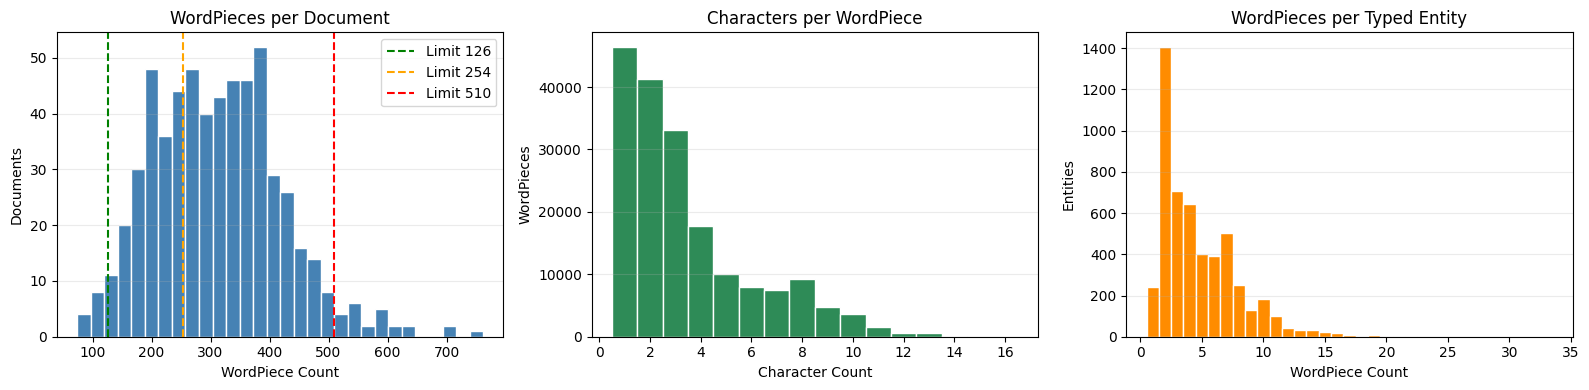

,Count,Percentage
Label,,
O,160047,86.722
B-SpecificDisease,2972,1.610
I-SpecificDisease,12461,6.752
B-DiseaseClass,769,0.417
I-DiseaseClass,2919,1.582
B-CompositeMention,115,0.062
I-CompositeMention,946,0.513
B-Modifier,1289,0.698
I-Modifier,3034,1.644


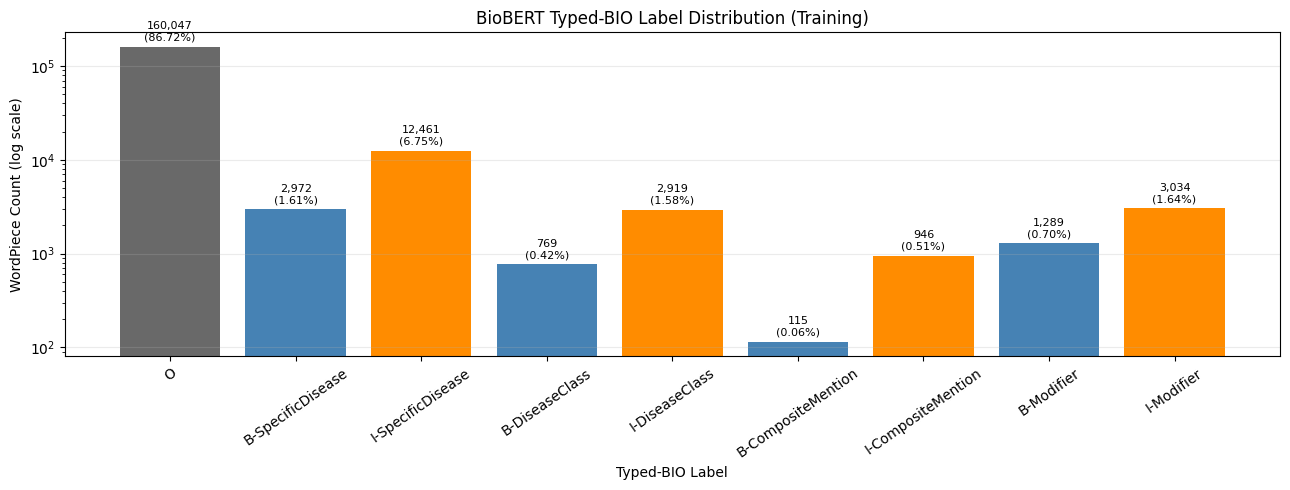

In [9]:
from collections import Counter

# Load all BioBERT-tokenized splits and validate the shared JSONL schema.
biobert_files = {
    "Training": "NCBI_training.jsonl",
    "Validation": "NCBI_validation.jsonl",
    "Testing": "NCBI_testing.jsonl",
}
biobert_records_by_split = {}
required_tokenized_fields = {
    "record_id",
    "pmid",
    "model",
    "tokenizer",
    "text",
    "entities",
    "tokens",
    "input_ids",
    "attention_mask",
    "offset_mapping",
    "bio_tags",
}

for split, file_name in biobert_files.items():
    file_path = biobert_output_dir / file_name
    with file_path.open(encoding="utf-8") as source:
        records = [
            json.loads(line) for line in source if line.strip()
        ]

    for record in records:
        missing_fields = required_tokenized_fields - set(record)
        if missing_fields:
            raise ValueError(
                f"Missing fields {sorted(missing_fields)} in "
                f"{record.get('record_id', file_name)}"
            )
        sequence_lengths = {
            len(record["tokens"]),
            len(record["input_ids"]),
            len(record["attention_mask"]),
            len(record["offset_mapping"]),
        }
        if len(sequence_lengths) != 1:
            raise ValueError(
                f"Token sequence mismatch in {record['record_id']}"
            )

        if split == "Training":
            if len(record["bio_tags"]) != len(record["tokens"]):
                raise ValueError(
                    f"BIO alignment mismatch in {record['record_id']}"
                )
        elif record["entities"] or record["bio_tags"]:
            raise ValueError(
                f"Gold labels are not masked in {record['record_id']}"
            )

    biobert_records_by_split[split] = records

# Preserve the original analysis scope: descriptive statistics use Training.
biobert_records = biobert_records_by_split["Training"]

# Summarise tokenization volume for every split without using masked gold.
split_token_rows = []
for split, records in biobert_records_by_split.items():
    split_token_counts = pd.Series([
        len(record["tokens"]) for record in records
    ])
    split_token_rows.append({
        "Split": split,
        "Documents": len(records),
        "Total WordPieces": int(split_token_counts.sum()),
        "Mean WordPieces": split_token_counts.mean(),
        "Median WordPieces": split_token_counts.median(),
        "95th Percentile": split_token_counts.quantile(0.95),
        "Maximum WordPieces": int(split_token_counts.max()),
        "Documents > 510": int((split_token_counts > 510).sum()),
    })
split_token_summary = pd.DataFrame(split_token_rows).set_index("Split")
display(split_token_summary.round(2))

document_token_counts = [
    len(record["tokens"]) for record in biobert_records
]
token_character_lengths = [
    token_end - token_start
    for record in biobert_records
    for token_start, token_end in record["offset_mapping"]
]

entity_wordpiece_counts = []
boundary_aligned_entities = 0

for record in biobert_records:
    offsets = record["offset_mapping"]
    token_starts = {token_start for token_start, _ in offsets}
    token_ends = {token_end for _, token_end in offsets}

    for entity in record["entities"]:
        wordpiece_count = sum(
            token_start < entity["end"]
            and token_end > entity["start"]
            for token_start, token_end in offsets
        )
        entity_wordpiece_counts.append(wordpiece_count)

        is_boundary_aligned = (
            entity["start"] in token_starts
            and entity["end"] in token_ends
        )
        boundary_aligned_entities += int(is_boundary_aligned)


def describe_values(name, values):
    values = pd.Series(values)
    return {
        "Measurement": name,
        "Count": len(values),
        "Mean": values.mean(),
        "Median": values.median(),
        "Minimum": values.min(),
        "95th Percentile": values.quantile(0.95),
        "Maximum": values.max(),
    }


token_statistics = pd.DataFrame([
    describe_values("WordPieces per document", document_token_counts),
    describe_values("Characters per WordPiece", token_character_lengths),
    describe_values("WordPieces per entity", entity_wordpiece_counts),
]).set_index("Measurement")
display(token_statistics.round(2))

# Reserve two positions for [CLS] and [SEP].
capacity_rows = []
for model_max_length in (128, 256, 512):
    content_limit = model_max_length - 2
    exceeding_count = sum(
        count > content_limit for count in document_token_counts
    )
    capacity_rows.append({
        "Model Max Length": model_max_length,
        "Content WordPiece Limit": content_limit,
        "Documents Exceeding Limit": exceeding_count,
        "Documents Exceeding Limit (%)": (
            exceeding_count / len(document_token_counts) * 100
        ),
    })

capacity_summary = pd.DataFrame(capacity_rows).set_index(
    "Model Max Length"
)
display(capacity_summary.round(2))

total_entities = len(entity_wordpiece_counts)
single_wordpiece_entities = sum(
    count == 1 for count in entity_wordpiece_counts
)
entity_alignment_summary = pd.DataFrame({
    "Metric": [
        "Single-WordPiece entities",
        "Multi-WordPiece entities",
        "Boundary-aligned entities",
        "Boundary-unaligned entities",
    ],
    "Count": [
        single_wordpiece_entities,
        total_entities - single_wordpiece_entities,
        boundary_aligned_entities,
        total_entities - boundary_aligned_entities,
    ],
}).set_index("Metric")
entity_alignment_summary["Percentage"] = (
    entity_alignment_summary["Count"] / total_entities * 100
)
display(entity_alignment_summary.round(2))

# Plot document, token, and entity tokenization distributions.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(
    document_token_counts,
    bins=30,
    color="steelblue",
    edgecolor="white",
)
for limit, color in zip((126, 254, 510), ("green", "orange", "red")):
    axes[0].axvline(
        limit,
        color=color,
        linestyle="--",
        label=f"Limit {limit}",
    )
axes[0].set_title("WordPieces per Document")
axes[0].set_xlabel("WordPiece Count")
axes[0].set_ylabel("Documents")
axes[0].legend()

token_length_bins = np.arange(
    0.5, max(token_character_lengths) + 1.5, 1
)
axes[1].hist(
    token_character_lengths,
    bins=token_length_bins,
    color="seagreen",
    edgecolor="white",
)
axes[1].set_title("Characters per WordPiece")
axes[1].set_xlabel("Character Count")
axes[1].set_ylabel("WordPieces")

entity_piece_bins = np.arange(
    0.5, max(entity_wordpiece_counts) + 1.5, 1
)
axes[2].hist(
    entity_wordpiece_counts,
    bins=entity_piece_bins,
    color="darkorange",
    edgecolor="white",
)
axes[2].set_title("WordPieces per Typed Entity")
axes[2].set_xlabel("WordPiece Count")
axes[2].set_ylabel("Entities")

for axis in axes:
    axis.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

# Analyse the 4 * 2 + 1 typed-BIO labels in the training split only.
training_label_counts = Counter(
    tag
    for record in biobert_records
    for tag in record["bio_tags"]
)
unknown_labels = set(training_label_counts) - set(BIO_LABELS)
if unknown_labels:
    raise ValueError(
        f"Unknown BIO labels found: {sorted(unknown_labels)}"
    )

label_distribution = pd.DataFrame({
    "Label": BIO_LABELS,
    "Count": [training_label_counts[label] for label in BIO_LABELS],
})
label_distribution["Percentage"] = (
    label_distribution["Count"]
    / label_distribution["Count"].sum()
    * 100
)
display(label_distribution.set_index("Label").round(3))

label_colors = [
    "dimgray"
    if label == "O"
    else "steelblue"
    if label.startswith("B-")
    else "darkorange"
    for label in label_distribution["Label"]
]
fig, axis = plt.subplots(figsize=(13, 5))
bars = axis.bar(
    label_distribution["Label"],
    label_distribution["Count"],
    color=label_colors,
)
axis.set_yscale("log")
axis.bar_label(
    bars,
    labels=[
        f"{count:,}\n({percentage:.2f}%)"
        for count, percentage in zip(
            label_distribution["Count"],
            label_distribution["Percentage"],
        )
    ],
    padding=3,
    fontsize=8,
)
axis.set_title("BioBERT Typed-BIO Label Distribution (Training)")
axis.set_xlabel("Typed-BIO Label")
axis.set_ylabel("WordPiece Count (log scale)")
axis.tick_params(axis="x", rotation=35)
axis.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 4. Entity-level evaluation

An exact match requires document, start, end and mention type to match. Micro F1 is the model selection and primary test metric. We also report macro F1, span-only F1, per-type scores, and type confusion restricted to exact span matches. Predictions are decoded once per document after averaging logits across overlapping windows. An illegal I transition starts a new entity and is counted before repair.

In [10]:
from collections import Counter
import json
from pathlib import Path

import pandas as pd

EVALUATION_ENTITY_TYPES = (
    "SpecificDisease",
    "DiseaseClass",
    "CompositeMention",
    "Modifier",
)


def load_jsonl_records(file_path):
    records = []
    with Path(file_path).open(encoding="utf-8") as source:
        for line_number, line in enumerate(source, start=1):
            if not line.strip():
                continue
            try:
                records.append(json.loads(line))
            except json.JSONDecodeError as error:
                raise ValueError(
                    f"Invalid JSON on line {line_number}: {file_path}"
                ) from error
    return records


def index_records(records, source_name):
    indexed = {}
    for record in records:
        record_id = record.get("record_id")
        if not isinstance(record_id, str) or not record_id:
            raise ValueError(f"Missing record_id in {source_name}")
        if record_id in indexed:
            raise ValueError(
                f"Duplicate record_id {record_id} in {source_name}"
            )
        indexed[record_id] = record
    return indexed


def validate_entity(entity, record_id, text_length):
    if not isinstance(entity, dict):
        raise TypeError(f"Entity in {record_id} must be a dictionary")
    if set(entity) != {"start", "end", "type"}:
        raise ValueError(
            f"Entity in {record_id} must contain only start, end, and type"
        )

    start, end = entity["start"], entity["end"]
    entity_type = entity["type"]
    valid_offsets = (
        isinstance(start, int)
        and not isinstance(start, bool)
        and isinstance(end, int)
        and not isinstance(end, bool)
    )
    if not valid_offsets or not 0 <= start < end <= text_length:
        raise ValueError(
            f"Invalid span [{start}, {end}) in {record_id}"
        )
    if entity_type not in EVALUATION_ENTITY_TYPES:
        raise ValueError(
            f"Invalid entity type {entity_type!r} in {record_id}"
        )
    return start, end, entity_type


def validate_prediction(prediction, gold_record):
    required_fields = {"record_id", "pmid", "entities"}
    if set(prediction) != required_fields:
        raise ValueError(
            f"Prediction {prediction.get('record_id')} must contain only "
            "record_id, pmid, and entities"
        )
    record_id = prediction["record_id"]
    if prediction["pmid"] != gold_record["pmid"]:
        raise ValueError(f"PMID mismatch for {record_id}")
    if not isinstance(prediction["entities"], list):
        raise ValueError(f"entities must be a list in {record_id}")

    text_length = len(gold_record["text"])
    entities = [
        validate_entity(entity, record_id, text_length)
        for entity in prediction["entities"]
    ]
    if entities != sorted(entities):
        raise ValueError(f"Entities are not sorted in {record_id}")
    if len(entities) != len(set(entities)):
        raise ValueError(f"Duplicate entities in {record_id}")

    spans = [(start, end) for start, end, _ in entities]
    if len(spans) != len(set(spans)):
        raise ValueError(
            f"A span has multiple predicted types in {record_id}"
        )
    return entities


def calculate_prf(tp, fp, fn):
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall
        else 0.0
    )
    return {
        "true_positives": tp,
        "false_positives": fp,
        "false_negatives": fn,
        "precision": precision,
        "recall": recall,
        "f1": f1,
    }


def set_counts(gold_values, predicted_values):
    return (
        len(gold_values & predicted_values),
        len(predicted_values - gold_values),
        len(gold_values - predicted_values),
    )


def boundary_counts(gold_values, predicted_values):
    gold_counter = Counter(gold_values)
    predicted_counter = Counter(predicted_values)
    return (
        sum((gold_counter & predicted_counter).values()),
        sum((predicted_counter - gold_counter).values()),
        sum((gold_counter - predicted_counter).values()),
    )


def spans_to_characters(spans):
    characters = set()
    for start, end in spans:
        characters.update(range(start, end))
    return characters


def add_counts(total, current):
    for index, value in enumerate(current):
        total[index] += value


def evaluate_standardized_records(gold_records, prediction_records):
    gold_by_id = index_records(gold_records, "gold records")
    pred_by_id = index_records(prediction_records, "predictions")
    missing = sorted(set(gold_by_id) - set(pred_by_id))
    extra = sorted(set(pred_by_id) - set(gold_by_id))
    if missing or extra:
        raise ValueError(
            f"Record mismatch: missing={missing}, extra={extra}"
        )

    typed_total = [0, 0, 0]
    span_only_total = [0, 0, 0]
    start_total = [0, 0, 0]
    end_total = [0, 0, 0]
    character_total = [0, 0, 0]
    per_type_totals = {
        entity_type: [0, 0, 0]
        for entity_type in EVALUATION_ENTITY_TYPES
    }
    type_confusion = {
        gold_type: {pred_type: 0 for pred_type in EVALUATION_ENTITY_TYPES}
        for gold_type in EVALUATION_ENTITY_TYPES
    }
    matched_span_count = 0
    correct_type_count = 0
    gold_entity_count = 0
    predicted_entity_count = 0

    for record_id, gold_record in gold_by_id.items():
        text_length = len(gold_record["text"])
        gold_entities = [
            validate_entity(entity, record_id, text_length)
            for entity in gold_record["entities"]
        ]
        predicted_entities = validate_prediction(
            pred_by_id[record_id], gold_record
        )

        gold_spans = [(start, end) for start, end, _ in gold_entities]
        predicted_spans = [
            (start, end) for start, end, _ in predicted_entities
        ]
        if len(gold_spans) != len(set(gold_spans)):
            raise ValueError(
                f"A gold span has multiple types in {record_id}"
            )

        gold_entity_count += len(gold_entities)
        predicted_entity_count += len(predicted_entities)
        gold_entity_set = set(gold_entities)
        predicted_entity_set = set(predicted_entities)
        gold_span_set = set(gold_spans)
        predicted_span_set = set(predicted_spans)

        add_counts(
            typed_total,
            set_counts(gold_entity_set, predicted_entity_set),
        )
        add_counts(
            span_only_total,
            set_counts(gold_span_set, predicted_span_set),
        )

        for entity_type in EVALUATION_ENTITY_TYPES:
            gold_for_type = {
                entity for entity in gold_entity_set
                if entity[2] == entity_type
            }
            predicted_for_type = {
                entity for entity in predicted_entity_set
                if entity[2] == entity_type
            }
            add_counts(
                per_type_totals[entity_type],
                set_counts(gold_for_type, predicted_for_type),
            )

        gold_type_by_span = {
            (start, end): entity_type
            for start, end, entity_type in gold_entities
        }
        predicted_type_by_span = {
            (start, end): entity_type
            for start, end, entity_type in predicted_entities
        }
        for span in gold_span_set & predicted_span_set:
            gold_type = gold_type_by_span[span]
            predicted_type = predicted_type_by_span[span]
            type_confusion[gold_type][predicted_type] += 1
            matched_span_count += 1
            correct_type_count += int(gold_type == predicted_type)

        add_counts(
            start_total,
            boundary_counts(
                [start for start, _ in gold_spans],
                [start for start, _ in predicted_spans],
            ),
        )
        add_counts(
            end_total,
            boundary_counts(
                [end for _, end in gold_spans],
                [end for _, end in predicted_spans],
            ),
        )
        add_counts(
            character_total,
            set_counts(
                spans_to_characters(gold_spans),
                spans_to_characters(predicted_spans),
            ),
        )

    per_type = {}
    for entity_type, counts in per_type_totals.items():
        values = calculate_prf(*counts)
        values["support"] = counts[0] + counts[2]
        values["predicted_count"] = counts[0] + counts[1]
        per_type[entity_type] = values

    typed_macro = {
        metric: sum(values[metric] for values in per_type.values())
        / len(EVALUATION_ENTITY_TYPES)
        for metric in ("precision", "recall", "f1")
    }
    wrong_type_count = matched_span_count - correct_type_count

    return {
        "averaging": "micro",
        "document_count": len(gold_by_id),
        "gold_entity_count": gold_entity_count,
        "predicted_entity_count": predicted_entity_count,
        "typed_exact": calculate_prf(*typed_total),
        "typed_macro": typed_macro,
        "per_type": per_type,
        "span_only_exact": calculate_prf(*span_only_total),
        "exact_span_type": {
            "matched_span_count": matched_span_count,
            "correct_type_count": correct_type_count,
            "wrong_type_count": wrong_type_count,
            "accuracy": (
                correct_type_count / matched_span_count
                if matched_span_count
                else 0.0
            ),
        },
        "type_confusion_matrix": type_confusion,
        "start_boundary": calculate_prf(*start_total),
        "end_boundary": calculate_prf(*end_total),
        "character_overlap": calculate_prf(*character_total),
    }


def evaluate_model_predictions(prediction_records, split):
    # Select the gold file while keeping one shared public evaluation entry point.
    if not isinstance(prediction_records, list):
        raise TypeError("prediction_records must be a list of dictionaries")
    if not all(isinstance(record, dict) for record in prediction_records):
        raise TypeError("Every prediction record must be a dictionary")

    if not isinstance(split, str):
        raise TypeError("split must be a string: 'validation' or 'test'")

    split_name = split.strip().lower()
    gold_file_names = {
        "validation": "NCBI_validation.jsonl",
        "test": "NCBI_testing.jsonl",
    }
    if split_name not in gold_file_names:
        raise ValueError("split must be 'validation' or 'test'")

    current_directory = Path.cwd().resolve()
    project_root = next(
        (
            path
            for path in (current_directory, *current_directory.parents)
            if (path / "Dataset" / "ProcessedData").is_dir()
        ),
        None,
    )
    if project_root is None:
        raise FileNotFoundError(
            "Could not locate Dataset/ProcessedData from the current directory"
        )

    gold_path = (
        project_root
        / "Dataset"
        / "ProcessedData"
        / gold_file_names[split_name]
    )
    return evaluate_standardized_records(
        load_jsonl_records(gold_path),
        prediction_records,
    )


def metrics_to_table(metrics):
    rows = []

    def append_prf_row(metric_name, values):
        rows.append({
            "Metric": metric_name,
            "TP": values.get("true_positives"),
            "FP": values.get("false_positives"),
            "FN": values.get("false_negatives"),
            "Precision": values["precision"],
            "Recall": values["recall"],
            "F1": values["f1"],
        })

    append_prf_row("Typed exact (micro)", metrics["typed_exact"])
    append_prf_row("Typed macro", metrics["typed_macro"])
    for entity_type in EVALUATION_ENTITY_TYPES:
        append_prf_row(
            f"Typed: {entity_type}",
            metrics["per_type"][entity_type],
        )
    append_prf_row("Span-only exact", metrics["span_only_exact"])
    append_prf_row("Start boundary", metrics["start_boundary"])
    append_prf_row("End boundary", metrics["end_boundary"])
    append_prf_row("Character overlap", metrics["character_overlap"])
    return pd.DataFrame(rows).set_index("Metric")


def type_confusion_to_table(metrics):
    table = pd.DataFrame.from_dict(
        metrics["type_confusion_matrix"], orient="index"
    )
    return table.reindex(
        index=EVALUATION_ENTITY_TYPES,
        columns=EVALUATION_ENTITY_TYPES,
        fill_value=0,
    ).rename_axis("Gold type").rename_axis("Predicted type", axis=1)


def save_metrics(metrics, output_path):
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    with output_path.open("w", encoding="utf-8") as destination:
        json.dump(metrics, destination, indent=2, ensure_ascii=False)


# Example usage after the model has produced prediction_records in memory:
# metrics = evaluate_model_predictions(prediction_records, "test")
# display(metrics_to_table(metrics).round(4))
# display(type_confusion_to_table(metrics))
# save_metrics(
#     metrics,
#     project_dir / "results" / "B1_test_metrics.json",
# )


print("Standardized evaluation functions are ready.")

Standardized evaluation functions are ready.


## 5. Experimental design

| ID | Adaptation | NER parameters updated |
|---|---|---|
| E1 | None | Classification head |
| E2 | None | Final four encoder layers and head |
| E3 | None | Entire encoder and head |
| E4 | Random WordPiece MLM | Entire encoder and head |
| E5 | Whole-word MLM | Entire encoder and head |
| E6 | Entity-aware span MLM | Entire encoder and head |

All runs start from the same pinned BioBERT revision. E2 and E3 each search three encoder learning rates on the official validation set using seed 42. E4–E6 inherit E3's selected NER configuration. E1 uses the head learning rate selected in the earlier validation-only baseline search. The three final seeds share matched initial classifier parameters and NER batch orders within each seed. The same early-stopping rule applies to every NER run. NER uses 512-token windows with a 64-token overlap. Training supervises overlapping tokens once.

E4–E6 use identical training documents, word-aligned block boundaries, and optimizer step budgets within each seed. E6 uses training annotation boundaries to choose complete mentions. It aims for half of its masking budget from entities, with whole-word selection filling the remainder. The report gives the realized mask fractions because complete words and spans constrain per-block budgets. E6's use of annotation boundaries makes it label-aware. Its comparison with E5 combines span geometry and entity targeting.

The formal test scores are produced after all configurations and checkpoints have been selected. The original baseline run already made one earlier E1 test score public. The legacy score is excluded from the matched comparison below.

In [11]:
LABELS = tuple(BIO_LABELS)


def make_windows(records, tokenizer, max_length, stride):
    """Keep full-document token indices; supervise overlap tokens only once."""
    capacity = max_length - 2
    if not 0 <= stride < capacity:
        raise ValueError('stride must be between 0 and max_length - 3')
    windows = []
    for doc, record in enumerate(records):
        ids, tags = record['input_ids'], record['bio_tags']
        if not len(ids) == len(tags) == len(record['offset_mapping']):
            raise ValueError(f"Unaligned tokens: {record['record_id']}")
        covered = 0
        for start in range(0, len(ids), capacity - stride):
            end = min(start + capacity, len(ids))
            labels = [LABEL2ID[tag] if i >= covered else -100
                      for i, tag in enumerate(tags[start:end], start)]
            windows.append({'doc': doc, 'start': start, 'end': end,
                            'input_ids': [tokenizer.cls_token_id] + ids[start:end] + [tokenizer.sep_token_id],
                            'labels': [-100] + labels + [-100]})
            covered = end
            if end == len(ids):
                break
    return windows


def decode_document(record, tag_ids):
    """Repair illegal I transitions as B; report their original count."""
    entities, active, illegal = [], None, 0
    for (start, end), label in zip(record['offset_mapping'], tag_ids):
        tag = BIO_LABELS[int(label)]
        prefix, kind = ('O', None) if tag == 'O' else tag.split('-', 1)
        if prefix == 'I' and (active is None or active['type'] != kind):
            illegal += 1
            prefix = 'B'
        if prefix != 'I' and active is not None:
            entities.append(active)
            active = None
        if prefix == 'B':
            active = {'start': start, 'end': end, 'type': kind}
        elif prefix == 'I':
            active['end'] = end
    if active is not None:
        entities.append(active)
    return {'record_id': record['record_id'], 'pmid': record['pmid'], 'entities': entities}, illegal

In [12]:
"""Train and compare six BioBERT disease NER experiments."""
from contextlib import nullcontext
from datetime import datetime, timezone
from hashlib import sha256
from pathlib import Path
import csv
import json
import math
import random
import statistics
import time

import torch
from torch.nn import functional as F
from transformers import AutoModelForMaskedLM, AutoModelForTokenClassification, BertConfig

# In the notebook these are the existing evaluator and window helpers.
if "__file__" in globals():
    from e1_head_only import (
        LABELS, decode_document, evaluate_standardized_records, load_jsonl_records,
        make_windows,
    )

BASE_MODEL = "dmis-lab/biobert-base-cased-v1.1"
BASE_REVISION = "924f12e0c3db7f156a765ad53fb6b11e7afedbc8"
TOKENIZER_REVISION = "cd5ef92a9fb2f889e972770a36d4ed042daf221e"
SCOPES = dict(E1="head", E2="last4", E3="full", E4="full", E5="full", E6="full")
STRATEGIES = dict(E4="token", E5="word", E6="entity")
DEFAULT_SEEDS = (42, 43, 44)
WINDOW = 512
OVERLAP = 64


def write_json(path, value):
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_suffix(".tmp")
    temp.write_text(json.dumps(value, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
    temp.replace(path)


def set_seed(seed):
    random.seed(seed)
    torch.manual_seed(seed)


def precision_context(device):
    if device.type == "cuda" and torch.cuda.is_bf16_supported():
        return torch.autocast("cuda", dtype=torch.bfloat16)
    return nullcontext()


def synchronize(device):
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()


def shuffled_batches(rows, size, rng=None):
    # Sorting within shuffled pools reduces padding while retaining different
    # training batches in each epoch. Evaluation order is length-sorted.
    indices = list(range(len(rows)))
    if rng is not None:
        rng.shuffle(indices)
    pools = [indices[i:i + size * 8] for i in range(0, len(indices), size * 8)]
    batches = []
    for pool in pools:
        pool.sort(key=lambda i: len(rows[i]["input_ids"]))
        batches.extend(pool[i:i + size] for i in range(0, len(pool), size))
    if rng is not None:
        rng.shuffle(batches)
    for batch in batches:
        yield [rows[i] for i in batch]


def collate(rows, tokenizer, device):
    length = math.ceil(max(len(row["input_ids"]) for row in rows) / 8) * 8
    ids, attention, labels = [], [], []
    for row in rows:
        pad = length - len(row["input_ids"])
        ids.append(row["input_ids"] + [tokenizer.pad_token_id] * pad)
        attention.append([1] * len(row["input_ids"]) + [0] * pad)
        if "labels" in row:
            labels.append(row["labels"] + [-100] * pad)
    inputs = {
        "input_ids": torch.tensor(ids, device=device),
        "attention_mask": torch.tensor(attention, device=device),
    }
    if labels:
        inputs["labels"] = torch.tensor(labels, device=device)
    return inputs


def read_ner_split(project, split, tokenizer, limit=None):
    cached = load_jsonl_records(project / "Dataset/TokenizedData/BioBERT" / f"NCBI_{split}.jsonl")
    gold = load_jsonl_records(project / "Dataset/ProcessedData" / f"NCBI_{split}.jsonl")
    if len(cached) != len(gold):
        raise ValueError(f"Tokenized and gold record counts differ for {split}")
    records = []
    for source, reference in zip(cached[:limit], gold[:limit], strict=True):
        if any(source[key] != reference[key] for key in ("record_id", "pmid", "text")):
            raise ValueError(f"Unaligned record {source['record_id']}")
        row = dict(source, entities=reference["entities"])
        if split != "training":
            row["bio_tags"] = ["O"] * len(row["input_ids"])
        records.append(row)
    return records, make_windows(records, tokenizer, WINDOW, OVERLAP)


def ner_config():
    return BertConfig.from_pretrained(
        BASE_MODEL, revision=BASE_REVISION, num_labels=len(LABELS),
        id2label=dict(enumerate(LABELS)),
        label2id={label: i for i, label in enumerate(LABELS)},
    )


def load_ner(scope, seed, device, adapted=None):
    set_seed(seed)
    source = str(adapted) if adapted else BASE_MODEL
    kwargs = {} if adapted else {"revision": BASE_REVISION}
    model = AutoModelForTokenClassification.from_pretrained(source, config=ner_config(), **kwargs)
    # Match the new NER head across adapted and unadapted models exactly.
    set_seed(seed)
    model.classifier.reset_parameters()
    head_hash = sha256(
        model.classifier.weight.detach().numpy().tobytes()
        + model.classifier.bias.detach().numpy().tobytes()
    ).hexdigest()
    if scope != "full":
        model.bert.requires_grad_(False)
        if scope == "last4":
            for layer in model.bert.encoder.layer[-4:]:
                layer.requires_grad_(True)
    return model.to(device), head_hash


@torch.inference_mode()
def score_ner(model, split, tokenizer, device, batch_size):
    records, windows = split
    model.eval()
    sums = [torch.zeros((len(r["input_ids"]), len(LABELS))) for r in records]
    counts = [torch.zeros(len(r["input_ids"])) for r in records]
    first = [torch.full((len(r["input_ids"]),), -1) for r in records]
    conflicts = [torch.zeros(len(r["input_ids"]), dtype=torch.bool) for r in records]
    for rows in shuffled_batches(windows, batch_size):
        inputs = collate(rows, tokenizer, device)
        inputs.pop("labels")
        with precision_context(device):
            logits = model(**inputs).logits.float().cpu()
        for row, values in zip(rows, logits, strict=True):
            doc, start, end = row["doc"], row["start"], row["end"]
            region = slice(start, end)
            values = values[1:1 + end - start]
            tag = values.argmax(-1)
            old = first[doc][region]
            conflicts[doc][region] |= (old >= 0) & (old != tag)
            first[doc][region] = tag
            sums[doc][region] += values
            counts[doc][region] += 1
    predictions, illegal = [], 0
    for record, total, count in zip(records, sums, counts, strict=True):
        if not torch.all(count > 0):
            raise ValueError(f"Uncovered document tokens in {record['record_id']}")
        pred, bad = decode_document(record, (total / count[:, None]).argmax(-1))
        predictions.append(pred)
        illegal += bad
    result = evaluate_standardized_records(records, predictions)
    result.update(
        illegal_bio_transitions=illegal,
        window_overlap_token_conflicts=sum(int(flags.sum()) for flags in conflicts),
    )
    return result, predictions


def train_ner(folder, experiment, seed, tokenizer, train, validation, device,
              encoder_lr, head_lr, epochs, min_epochs, patience, batch_size, adapted=None,
              evaluate_train=True):
    scope = SCOPES[experiment]
    model, head_hash = load_ner(scope, seed, device, adapted)
    encoder = [p for p in model.bert.parameters() if p.requires_grad]
    head = list(model.classifier.parameters())
    parameters = encoder + head
    groups = [{"params": head, "lr": head_lr}]
    if encoder:
        groups.append({"params": encoder, "lr": encoder_lr})
    optimizer = torch.optim.AdamW(groups, weight_decay=0.01, fused=device.type == "cuda")
    config = dict(
        experiment=experiment, seed=seed, scope=scope, base_model=BASE_MODEL,
        base_revision=BASE_REVISION, tokenizer_revision=TOKENIZER_REVISION,
        adapted=str(adapted) if adapted else None, head_init_sha256=head_hash,
        encoder_lr=encoder_lr if encoder else None, head_lr=head_lr, epochs=epochs,
        min_epochs=min_epochs, patience=patience, batch_size=batch_size,
        max_length=WINDOW, overlap=OVERLAP, optimizer="AdamW",
        weight_decay=0.01, gradient_clip=1.0, device=str(device),
        trainable_parameters=sum(p.numel() for p in parameters),
    )
    write_json(folder / "config.json", config)
    best_state, best, best_epoch, stale = None, -1, 0, 0
    history, optimization_seconds = [], 0.0
    wall_start = time.perf_counter()
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    for epoch in range(1, epochs + 1):
        model.train()
        if scope == "head":
            model.bert.eval()
        elif scope == "last4":
            model.bert.embeddings.eval()
            for layer in model.bert.encoder.layer[:-4]:
                layer.eval()
        set_seed(seed + 1000 * epoch)
        losses = torch.zeros((), device=device)
        tokens = 0
        train_start = time.perf_counter()
        for rows in shuffled_batches(train[1], batch_size, random.Random(seed + epoch)):
            inputs = collate(rows, tokenizer, device)
            count = sum(sum(tag != -100 for tag in row["labels"]) for row in rows)
            optimizer.zero_grad(set_to_none=True)
            with precision_context(device):
                loss = model(**inputs).loss
            loss.backward()
            torch.nn.utils.clip_grad_norm_(parameters, 1.0)
            optimizer.step()
            losses += loss.detach() * count
            tokens += count
        synchronize(device)
        optimization_seconds += time.perf_counter() - train_start
        validation_metrics, predictions = score_ner(model, validation, tokenizer, device, batch_size)
        f1 = validation_metrics["typed_exact"]["f1"]
        train_loss = losses.item() / tokens
        if not math.isfinite(train_loss):
            raise FloatingPointError(f"Nonfinite NER loss in {experiment} seed {seed}")
        history.append(dict(epoch=epoch, train_loss=train_loss, validation_f1=f1))
        write_json(folder / "history.json", history)
        if f1 > best:
            best, best_epoch, stale = f1, epoch, 0
            best_state = {k: p.detach().cpu().clone() for k, p in model.state_dict().items()}
            write_json(folder / "validation_metrics.json", validation_metrics)
            write_json(folder / "validation_predictions.json", predictions)
        else:
            stale += 1
        print(f"{experiment} seed={seed} epoch={epoch:02} loss={train_loss:.4f} "
              f"val_f1={f1:.4f}", flush=True)
        if epoch >= min_epochs and stale >= patience:
            break
    peak = torch.cuda.max_memory_allocated() if device.type == "cuda" else None
    model.load_state_dict(best_state)
    checkpoint = folder / "best_checkpoint"
    model.save_pretrained(checkpoint)
    tokenizer.save_pretrained(checkpoint)
    wall_seconds = time.perf_counter() - wall_start
    if evaluate_train:
        metrics, _ = score_ner(model, train, tokenizer, device, batch_size)
        write_json(folder / "training_metrics.json", metrics)
    summary = dict(
        best_epoch=best_epoch, completed_epochs=len(history), validation_f1=best,
        optimization_seconds=optimization_seconds, wall_seconds=wall_seconds,
        peak_cuda_bytes=peak, trainable_parameters=config["trainable_parameters"],
    )
    write_json(folder / "summary.json", summary)
    return summary


def make_mlm_splits(records, tokenizer, seed, block_size=256):
    by_pmid = {}
    for record in records:
        pmid = record["pmid"]
        if pmid in by_pmid:
            previous = by_pmid[pmid]
            if any(record[k] != previous[k] for k in ("text", "entities")):
                raise ValueError(f"Conflicting records for duplicate PMID {pmid}")
        by_pmid.setdefault(pmid, record)
    pmids = sorted(by_pmid)
    random.Random(seed).shuffle(pmids)
    cutoff = max(1, round(len(pmids) * 0.1))
    groups = dict(training=pmids[cutoff:], validation=pmids[:cutoff])
    blocks = {}
    for split, keys in groups.items():
        blocks[split] = []
        for pmid in keys:
            record = by_pmid[pmid]
            # Tokenizer offsets and word IDs agree with the full NER input.
            encoded = tokenizer(record["text"], add_special_tokens=False, return_offsets_mapping=True,
                                verbose=False)
            if encoded["input_ids"] != record["input_ids"]:
                raise ValueError(f"MLM tokenization mismatch for {pmid}")
            word_ids = encoded.word_ids()
            words = []
            for index, word_id in enumerate(word_ids):
                if index == 0 or word_id != word_ids[index - 1]:
                    words.append([])
                words[-1].append(index)
            # BIO spans use the same corrected training offsets as NER.
            entities, active = [], []
            for i, tag in enumerate(record["bio_tags"]):
                if not tag.startswith("I-") and active:
                    entities.append(active)
                    active = []
                if tag != "O":
                    active.append(i)
            if active:
                entities.append(active)
            allowed_ends = {group[-1] + 1 for group in words}
            start = 0
            while start < len(word_ids):
                end = min(start + block_size - 2, len(word_ids))
                while end > start and end not in allowed_ends:
                    end -= 1
                if end == start:
                    raise ValueError(f"Word longer than MLM capacity for {pmid}")
                blocks[split].append(dict(
                    input_ids=[tokenizer.cls_token_id] + record["input_ids"][start:end]
                    + [tokenizer.sep_token_id],
                    words=[[i - start + 1 for i in g] for g in words if start <= g[0] < end],
                    entities=[[i - start + 1 for i in g] for g in entities
                              if start <= g[0] and g[-1] < end],
                    entity_tokens={i - start + 1 for g in entities for i in g if start <= i < end},
                ))
                start = end
    return blocks, groups


def fit_groups(groups, budget, rng):
    """Select whole groups without exceeding budget, preferring a full budget."""
    groups = list(groups)
    rng.shuffle(groups)
    picked = []
    for group in groups:
        if len(group) <= budget:
            picked.extend(group)
            budget -= len(group)
            if budget == 0:
                break
    return picked


def mask_row(row, strategy, tokenizer, rng):
    ids = row["input_ids"]
    budget = max(1, round((len(ids) - 2) * 0.15))
    if strategy == "token":
        picked = rng.sample(range(1, len(ids) - 1), budget)
        entity_count = 0
    elif strategy == "word" or not row["entities"]:
        picked = fit_groups(row["words"], budget, rng)
        entity_count = 0
    else:
        entities = row["entities"]
        entity_tokens = row["entity_tokens"]
        non_entity_words = [group for group in row["words"] if entity_tokens.isdisjoint(group)]
        # Prefer half the budget from complete mentions and backfill with
        # non-entity words. Fallback can include additional complete mentions.
        picked = fit_groups(entities, round(budget / 2), rng)
        entity_count = len(picked)
        picked += fit_groups(non_entity_words, budget - len(picked), rng)
        picked_set = set(picked)
        unused = [span for span in entities if picked_set.isdisjoint(span)]
        extra = fit_groups(unused, budget - len(picked), rng)
        picked += extra
        entity_count += len(extra)
    if not picked:
        # Whole groups can exceed the nominal budget for a very short block.
        candidates = row["words"] if strategy != "entity" else [
            *row["entities"], *[g for g in row["words"]
                                 if row["entity_tokens"].isdisjoint(g)]
        ]
        picked = min(candidates, key=len)
        entity_count = len(picked) if strategy == "entity" and picked in row["entities"] else 0
    inputs, labels = ids.copy(), [-100] * len(ids)
    for i in picked:
        labels[i] = ids[i]
        draw = rng.random()
        if draw < 0.8:
            inputs[i] = tokenizer.mask_token_id
        elif draw < 0.9:
            inputs[i] = rng.randrange(len(tokenizer))
    return dict(input_ids=inputs, labels=labels), len(picked), entity_count


def mlm_loss(model, inputs):
    labels = inputs.pop("labels")
    selected = labels != -100
    hidden = model.bert(**inputs).last_hidden_state
    # Apply the vocabulary projection only at positions that contribute to loss.
    logits = model.cls(hidden[selected])
    return F.cross_entropy(logits, labels[selected])


def run_mlm_epoch(model, rows, strategy, tokenizer, device, seed, batch_size,
                  optimizer=None, scheduler=None):
    training = optimizer is not None
    model.train(training)
    rng = random.Random(seed)
    loss_sum = torch.zeros((), device=device)
    total, targeted, eligible = 0, 0, 0
    context = nullcontext() if training else torch.inference_mode()
    with context:
        for batch in shuffled_batches(rows, batch_size, rng if training else None):
            masked = [mask_row(row, strategy, tokenizer, rng) for row in batch]
            inputs = collate([item[0] for item in masked], tokenizer, device)
            count = sum(item[1] for item in masked)
            if training:
                optimizer.zero_grad(set_to_none=True)
            with precision_context(device):
                loss = mlm_loss(model, inputs)
            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
                scheduler.step()
            loss_sum += loss.detach() * count
            total += count
            targeted += sum(item[2] for item in masked)
            eligible += sum(len(row["input_ids"]) - 2 for row in batch)
    return dict(loss=loss_sum.item() / total, masked=total, eligible=eligible,
                mask_fraction=total / eligible, entity_targeted=targeted)


def train_mlm(folder, experiment, seed, tokenizer, data, groups, device, epochs, batch_size):
    strategy = STRATEGIES[experiment]
    set_seed(seed)
    config = BertConfig.from_pretrained(BASE_MODEL, revision=BASE_REVISION)
    # The original checkpoint contains separate decoder and embedding tensors.
    config.tie_word_embeddings = False
    model, loading = AutoModelForMaskedLM.from_pretrained(
        BASE_MODEL, revision=BASE_REVISION, config=config, output_loading_info=True,
    )
    if loading["missing_keys"] or loading["mismatched_keys"]:
        raise RuntimeError(f"Incomplete BioBERT MLM initialization: {loading}")
    model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=5e-5, weight_decay=0.01,
                                  fused=device.type == "cuda")
    steps = epochs * math.ceil(len(data["training"]) / batch_size)
    warmup = max(1, round(steps * 0.10))
    def lr_multiplier(step):
        if step < warmup:
            return (step + 1) / warmup
        return max(0.0, (steps - step) / max(1, steps - warmup))

    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_multiplier)
    write_json(folder / "config.json", dict(
        experiment=experiment, strategy=strategy, seed=seed, epochs=epochs,
        base_model=BASE_MODEL, revision=BASE_REVISION, lr=5e-5, weight_decay=0.01,
        batch_size=batch_size, optimizer_steps=steps, block_size=256, target_mask_fraction=0.15,
        checkpoint_policy="fixed final optimization step", split=groups,
    ))
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    started = time.perf_counter()
    history, optimization_seconds = [], 0.0
    for epoch in range(1, epochs + 1):
        set_seed(seed + 1000 * epoch)
        train_start = time.perf_counter()
        train = run_mlm_epoch(model, data["training"], strategy, tokenizer, device,
                              seed + epoch, batch_size, optimizer, scheduler)
        synchronize(device)
        optimization_seconds += time.perf_counter() - train_start
        valid = run_mlm_epoch(model, data["validation"], strategy, tokenizer, device,
                              seed + 100_000, batch_size)
        if not all(math.isfinite(item["loss"]) for item in (train, valid)):
            raise FloatingPointError(f"Nonfinite MLM loss in {experiment} seed {seed}")
        history.append(dict(epoch=epoch, training=train, validation=valid))
        write_json(folder / "history.json", history)
        print(f"{experiment} MLM seed={seed} epoch={epoch:02} train_loss={train['loss']:.4f} "
              f"val_loss={valid['loss']:.4f} mask={train['mask_fraction']:.4f}", flush=True)
    peak = torch.cuda.max_memory_allocated() if device.type == "cuda" else None
    checkpoint = folder / "final_checkpoint"
    model.save_pretrained(checkpoint)
    tokenizer.save_pretrained(checkpoint)
    write_json(folder / "summary.json", dict(
        optimization_seconds=optimization_seconds, wall_seconds=time.perf_counter() - started,
        peak_cuda_bytes=peak, optimizer_steps=steps,
        mask_fraction=sum(item["training"]["masked"] for item in history)
        / sum(item["training"]["eligible"] for item in history),
        entity_mask_fraction=sum(item["training"]["entity_targeted"] for item in history)
        / sum(item["training"]["masked"] for item in history),
    ))
    return checkpoint


def read_json(path):
    return json.loads(path.read_text(encoding="utf-8"))


def aggregate(run_dir, seeds):
    rows = []
    for experiment in SCOPES:
        for seed in seeds:
            folder = run_dir / experiment / str(seed)
            result = read_json(folder / "test_metrics.json")
            summary = read_json(folder / "summary.json")
            train = read_json(folder / "training_metrics.json")
            strict = result["typed_exact"]
            rows.append(dict(
                experiment=experiment, seed=seed, precision=strict["precision"],
                recall=strict["recall"], micro_f1=strict["f1"],
                macro_f1=result["typed_macro"]["f1"], span_f1=result["span_only_exact"]["f1"],
                validation_f1=summary["validation_f1"], training_f1=train["typed_exact"]["f1"],
                illegal_bio=result["illegal_bio_transitions"],
                overlap_conflicts=result["window_overlap_token_conflicts"],
                best_epoch=summary["best_epoch"], ner_seconds=summary["optimization_seconds"],
                ner_wall_seconds=summary["wall_seconds"],
                ner_peak_cuda_bytes=summary["peak_cuda_bytes"],
                trainable_parameters=summary["trainable_parameters"],
                **({f"mlm_{k}": v for k, v in read_json(folder / "mlm/summary.json").items()}
                   if experiment in STRATEGIES else {}),
            ))
    reference = {row["seed"]: row["micro_f1"] for row in rows if row["experiment"] == "E3"}
    for row in rows:
        row["delta_vs_e3"] = row["micro_f1"] - reference[row["seed"]]
    stats = {}
    for exp in SCOPES:
        group = [row for row in rows if row["experiment"] == exp]
        stats[exp] = {
            key: dict(mean=statistics.mean(values), sd=statistics.stdev(values) if len(values) > 1 else None)
            for key in group[0] if key not in {"experiment", "seed"}
            if (values := [row[key] for row in group if row[key] is not None])
        }
    write_json(run_dir / "results.json", dict(seeds=list(seeds), runs=rows, summary=stats))
    fields = list(dict.fromkeys(key for row in rows for key in row))
    with (run_dir / "results.csv").open("w", encoding="utf-8", newline="") as file:
        writer = csv.DictWriter(file, fieldnames=fields)
        writer.writeheader()
        writer.writerows(rows)
    return stats


def run_study(project, tokenizer, run_dir, *, seeds=DEFAULT_SEEDS, smoke=False, source_sha=None):
    run_dir.mkdir(parents=True, exist_ok=True)
    device = torch.device("cuda" if torch.cuda.is_available() else
                          "mps" if torch.backends.mps.is_available() else "cpu")
    batch_size = 16 if device.type == "cuda" else 4
    mlm_batch_size = 32 if device.type == "cuda" else 4
    # Fixed budgets preserve matched downstream settings for E3–E6.
    ner_epochs, min_epochs, patience = (1, 1, 1) if smoke else (30, 8, 4)
    mlm_epochs = 1 if smoke else 10
    seeds = tuple(seeds)
    limit = 8 if smoke else None
    train = read_ner_split(project, "training", tokenizer, limit)
    val = read_ner_split(project, "validation", tokenizer, limit)
    study = dict(
        seeds=list(seeds), smoke=smoke, source_sha256=source_sha, device=str(device),
        torch_version=str(torch.__version__),
        transformers_version=__import__("transformers").__version__,
        device_name=torch.cuda.get_device_name() if device.type == "cuda" else str(device),
        precision="bfloat16 mixed" if device.type == "cuda" and torch.cuda.is_bf16_supported()
        else "float32",
        ner_epochs=ner_epochs, min_epochs=min_epochs, patience=patience,
        batch_size=batch_size, mlm_epochs=mlm_epochs, mlm_batch_size=mlm_batch_size,
        base_revision=BASE_REVISION, tokenizer_revision=TOKENIZER_REVISION,
        raw_sha256={path.name: sha256(path.read_bytes()).hexdigest() for path in
                    sorted((project / "Dataset/RawData").glob("NCBI_*.txt"))},
    )
    if (run_dir / "study.json").exists() and read_json(run_dir / "study.json") != study:
        raise ValueError("Existing run directory uses different study settings")
    write_json(run_dir / "study.json", study)
    if device.type == "cuda":
        torch.set_float32_matmul_precision("high")
    shared = dict(tokenizer=tokenizer, train=train, validation=val, device=device,
                  epochs=ner_epochs, min_epochs=min_epochs, patience=patience, batch_size=batch_size)
    # E1 uses the original validation-selected head LR. E2/E3 receive identical
    # validation search budgets, and E3's selection is locked for E4–E6.
    choices = [2e-5] if smoke else [1e-5, 2e-5, 3e-5]
    selected = {}
    for experiment in ("E2", "E3"):
        trials = {}
        for lr in choices:
            folder = run_dir / "tuning" / experiment / f"{lr:g}"
            if (folder / "summary.json").exists():
                summary = read_json(folder / "summary.json")
            else:
                summary = train_ner(folder, experiment, seeds[0], encoder_lr=lr,
                                    head_lr=1e-4, evaluate_train=True, **shared)
            trials[lr] = summary["validation_f1"]
        selected[experiment] = max(choices, key=trials.get)
        write_json(run_dir / "tuning" / f"{experiment}.json", dict(selected=selected[experiment],
                                                                  validation_f1=trials))
    for seed in seeds:
        # Same deterministic document partition for the three MLM strategies.
        mlm_data, groups = make_mlm_splits(train[0], tokenizer, seed)
        for experiment in SCOPES:
            folder = run_dir / experiment / str(seed)
            if (folder / "summary.json").exists():
                continue
            adapted = None
            if experiment in STRATEGIES:
                mlm_dir = folder / "mlm"
                if (mlm_dir / "summary.json").exists():
                    adapted = mlm_dir / "final_checkpoint"
                else:
                    adapted = train_mlm(mlm_dir, experiment, seed, tokenizer, mlm_data,
                                        groups, device, mlm_epochs, mlm_batch_size)
            if experiment in selected and seed == seeds[0]:
                # Reuse the validation-selected run. The same candidate would
                # otherwise be retrained on the same seed with identical settings.
                import shutil
                source = run_dir / "tuning" / experiment / f"{selected[experiment]:g}"
                shutil.copytree(source, folder, dirs_exist_ok=True,
                                ignore=shutil.ignore_patterns("summary.json"))
                write_json(folder / "summary.json", read_json(source / "summary.json"))
            else:
                train_ner(folder, experiment, seed, encoder_lr=selected.get(experiment, selected["E3"]),
                          head_lr=1e-3 if experiment == "E1" else 1e-4, adapted=adapted, **shared)
    write_json(run_dir / "selection_frozen.json", dict(
        rule="highest validation typed exact-span micro F1", selected_encoder_lr=selected,
        head_lr=dict(E1=1e-3, E2_to_E6=1e-4), seeds=list(seeds),
    ))
    # Test is first loaded here, after every experiment has been trained and selected.
    test = read_ner_split(project, "testing", tokenizer, limit)
    for seed in seeds:
        for experiment in SCOPES:
            folder = run_dir / experiment / str(seed)
            if (folder / "test_metrics.json").exists():
                continue
            model = AutoModelForTokenClassification.from_pretrained(folder / "best_checkpoint").to(device)
            metrics, predictions = score_ner(model, test, tokenizer, device, batch_size)
            write_json(folder / "test_predictions.json", predictions)
            write_json(folder / "test_metrics.json", metrics)
            print(f"TEST {experiment} seed={seed} micro_f1={metrics['typed_exact']['f1']:.4f}",
                  flush=True)
            del model
    return aggregate(run_dir, seeds)


def study_cli():
    import argparse
    from transformers import AutoTokenizer

    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--run-dir", type=Path)
    parser.add_argument("--seeds", type=int, nargs="+", default=DEFAULT_SEEDS)
    parser.add_argument("--smoke", action="store_true")
    args = parser.parse_args()
    if len(set(args.seeds)) != len(args.seeds):
        parser.error("Seeds must be distinct")
    project = Path(__file__).resolve().parent
    run_dir = args.run_dir or project / "results" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S")
    tokenizer = AutoTokenizer.from_pretrained("google-bert/bert-base-cased",
                                              revision=TOKENIZER_REVISION, use_fast=True)
    source_sha = sha256(Path(__file__).read_bytes()).hexdigest()
    run_study(project, tokenizer, run_dir.resolve(), seeds=args.seeds, smoke=args.smoke,
              source_sha=source_sha)


if globals().get("__file__", "").endswith("bio_ner_study.py") and __name__ == "__main__":
    study_cli()

## 6. Reproduce the study

Set **REPLAY_STUDY = True** to train all six variants and save per-run configurations, histories, checkpoints and predictions. This cell displays the replay summary. Section 7 displays the archived run.

In [13]:
REPLAY_STUDY = False
if REPLAY_STUDY:
    replay_dir = Path(project_dir) / "results" / datetime.now(timezone.utc).strftime("replay-%Y%m%dT%H%M%S")
    replay_summary = run_study(Path(project_dir), biobert_tokenizer, replay_dir)
    display(pd.DataFrame({exp: stats["micro_f1"] for exp, stats in replay_summary.items()}).T)
    print("Replay artifacts:", replay_dir)

## 7. Recorded results

In [14]:
recorded = json.loads(r'''{"seeds":[42,43,44],"runs":[{"experiment":"E1","seed":42,"precision":0.3509887005649718,"recall":0.5177083333333333,"micro_f1":0.41835016835016836,"macro_f1":0.2778563742383836,"span_f1":0.4318181818181818,"validation_f1":0.4027703782631859,"training_f1":0.45930968967701075,"illegal_bio":577,"overlap_conflicts":0,"best_epoch":26,"ner_seconds":12.616697900002691,"ner_wall_seconds":17.84064480000052,"ner_peak_cuda_bytes":702296576,"trainable_parameters":6921,"delta_vs_e3":-0.37809251939686717},{"experiment":"E1","seed":43,"precision":0.3518900343642612,"recall":0.5333333333333333,"micro_f1":0.424016563146998,"macro_f1":0.28403173841520246,"span_f1":0.4347826086956521,"validation_f1":0.40628272251308895,"training_f1":0.47273012634387507,"illegal_bio":609,"overlap_conflicts":1,"best_epoch":28,"ner_seconds":12.591627400006473,"ner_wall_seconds":17.83925839999938,"ner_peak_cuda_bytes":702296576,"trainable_parameters":6921,"delta_vs_e3":-0.3747882177294961},{"experiment":"E1","seed":44,"precision":0.3543252595155709,"recall":0.5333333333333333,"micro_f1":0.42577962577962575,"macro_f1":0.28635413108952773,"span_f1":0.4382536382536383,"validation_f1":0.4033525405971713,"training_f1":0.47089242341142357,"illegal_bio":607,"overlap_conflicts":0,"best_epoch":27,"ner_seconds":12.415163600002415,"ner_wall_seconds":17.761269399999946,"ner_peak_cuda_bytes":702296576,"trainable_parameters":6921,"delta_vs_e3":-0.34690330104964257},{"experiment":"E2","seed":42,"precision":0.6504347826086957,"recall":0.7791666666666667,"micro_f1":0.7090047393364929,"macro_f1":0.5750248018268268,"span_f1":0.7450236966824645,"validation_f1":0.7117852975495916,"training_f1":0.9928266770065917,"illegal_bio":167,"overlap_conflicts":4,"best_epoch":25,"ner_seconds":20.337674200001857,"ner_wall_seconds":25.023314500000197,"ner_peak_cuda_bytes":2006280704,"trainable_parameters":28358409,"delta_vs_e3":-0.08743794841054264},{"experiment":"E2","seed":43,"precision":0.6610169491525424,"recall":0.771875,"micro_f1":0.712157616530514,"macro_f1":0.5900028751130016,"span_f1":0.746756367131187,"validation_f1":0.6981903093987157,"training_f1":0.9880917804240489,"illegal_bio":153,"overlap_conflicts":1,"best_epoch":22,"ner_seconds":18.257520800001657,"ner_wall_seconds":22.879223300000376,"ner_peak_cuda_bytes":2012572160,"trainable_parameters":28358409,"delta_vs_e3":-0.08664716434598008},{"experiment":"E2","seed":44,"precision":0.631979695431472,"recall":0.778125,"micro_f1":0.6974789915966386,"macro_f1":0.5775365533271654,"span_f1":0.7273576097105509,"validation_f1":0.6961069145845438,"training_f1":0.9944729952487151,"illegal_bio":181,"overlap_conflicts":6,"best_epoch":30,"ner_seconds":20.970605399994383,"ner_wall_seconds":26.27425410000069,"ner_peak_cuda_bytes":2012310016,"trainable_parameters":28358409,"delta_vs_e3":-0.07520393523262969},{"experiment":"E3","seed":42,"precision":0.7575187969924813,"recall":0.8395833333333333,"micro_f1":0.7964426877470355,"macro_f1":0.733494899562828,"span_f1":0.8369565217391305,"validation_f1":0.8193069306930694,"training_f1":0.9877045212508471,"illegal_bio":59,"overlap_conflicts":0,"best_epoch":12,"ner_seconds":21.678305100000216,"ner_wall_seconds":24.213815999999497,"ner_peak_cuda_bytes":5003490304,"trainable_parameters":107726601,"delta_vs_e3":0.0},{"experiment":"E3","seed":43,"precision":0.7652671755725191,"recall":0.8354166666666667,"micro_f1":0.7988047808764941,"macro_f1":0.7106061015801011,"span_f1":0.849601593625498,"validation_f1":0.8170055452865064,"training_f1":0.9935996896819239,"illegal_bio":43,"overlap_conflicts":2,"best_epoch":13,"ner_seconds":23.020593199998984,"ner_wall_seconds":25.696742500000255,"ner_peak_cuda_bytes":5002068992,"trainable_parameters":107726601,"delta_vs_e3":0.0},{"experiment":"E3","seed":44,"precision":0.726605504587156,"recall":0.825,"micro_f1":0.7726829268292683,"macro_f1":0.7106304246813291,"span_f1":0.8214634146341463,"validation_f1":0.8111718275652702,"training_f1":0.9356803044719314,"illegal_bio":95,"overlap_conflicts":6,"best_epoch":6,"ner_seconds":13.5060437000011,"ner_wall_seconds":15.230791399999362,"ner_peak_cuda_bytes":5006722048,"trainable_parameters":107726601,"delta_vs_e3":0.0},{"experiment":"E4","seed":42,"precision":0.7302025782688766,"recall":0.8260416666666667,"micro_f1":0.775171065493646,"macro_f1":0.6716543573875572,"span_f1":0.8250244379276637,"validation_f1":0.8058787507654623,"training_f1":0.9726185885075203,"illegal_bio":70,"overlap_conflicts":0,"best_epoch":9,"ner_seconds":17.556997499999852,"ner_wall_seconds":19.993754799999806,"ner_peak_cuda_bytes":5005411328,"trainable_parameters":107726601,"mlm_optimization_seconds":85.35421310000311,"mlm_wall_seconds":96.06595879999986,"mlm_peak_cuda_bytes":5519218176,"mlm_optimizer_steps":290,"mlm_mask_fraction":0.14991546914623838,"mlm_entity_mask_fraction":0.0,"delta_vs_e3":-0.02127162225338952},{"experiment":"E4","seed":43,"precision":0.75187265917603,"recall":0.8364583333333333,"micro_f1":0.7919132149901382,"macro_f1":0.7443571203304709,"span_f1":0.8392504930966469,"validation_f1":0.8151311775472848,"training_f1":0.9949534161490683,"illegal_bio":59,"overlap_conflicts":0,"best_epoch":14,"ner_seconds":24.275050600002942,"ner_wall_seconds":27.32929949999925,"ner_peak_cuda_bytes":5002068992,"trainable_parameters":107726601,"mlm_optimization_seconds":84.55343410000023,"mlm_wall_seconds":94.54809810000006,"mlm_peak_cuda_bytes":5521006080,"mlm_optimizer_steps":290,"mlm_mask_fraction":0.14992341270562023,"mlm_entity_mask_fraction":0.0,"delta_vs_e3":-0.006891565886355866},{"experiment":"E4","seed":44,"precision":0.7446009389671362,"recall":0.8260416666666667,"micro_f1":0.7832098765432098,"macro_f1":0.7229043084157427,"span_f1":0.8256790123456791,"validation_f1":0.8129272840273462,"training_f1":0.9738290680830516,"illegal_bio":87,"overlap_conflicts":0,"best_epoch":8,"ner_seconds":16.19371279999723,"ner_wall_seconds":18.389661699999124,"ner_peak_cuda_bytes":5006722048,"trainable_parameters":107726601,"mlm_optimization_seconds":86.5575164000038,"mlm_wall_seconds":95.64618439999867,"mlm_peak_cuda_bytes":5520678400,"mlm_optimizer_steps":290,"mlm_mask_fraction":0.14991673303888206,"mlm_entity_mask_fraction":0.0,"delta_vs_e3":0.010526949713941525},{"experiment":"E5","seed":42,"precision":0.7741935483870968,"recall":0.85,"micro_f1":0.810327706057597,"macro_f1":0.7217593904673069,"span_f1":0.8490566037735849,"validation_f1":0.8202933985330073,"training_f1":0.9699364039313934,"illegal_bio":50,"overlap_conflicts":2,"best_epoch":8,"ner_seconds":16.229828200004704,"ner_wall_seconds":18.411728300001414,"ner_peak_cuda_bytes":5005411328,"trainable_parameters":107726601,"mlm_optimization_seconds":87.4812550000006,"mlm_wall_seconds":97.48509310000009,"mlm_peak_cuda_bytes":5519218176,"mlm_optimizer_steps":290,"mlm_mask_fraction":0.14991546914623838,"mlm_entity_mask_fraction":0.0,"delta_vs_e3":0.013885018310561437},{"experiment":"E5","seed":43,"precision":0.7444237918215614,"recall":0.834375,"micro_f1":0.7868369351669942,"macro_f1":0.7251427649001658,"span_f1":0.8369351669941061,"validation_f1":0.8163514338010982,"training_f1":0.9787480680061823,"illegal_bio":66,"overlap_conflicts":8,"best_epoch":9,"ner_seconds":17.635263600001053,"ner_wall_seconds":19.988031200000478,"ner_peak_cuda_bytes":5002068992,"trainable_parameters":107726601,"mlm_optimization_seconds":84.94148309999946,"mlm_wall_seconds":94.17163110000001,"mlm_peak_cuda_bytes":5521006080,"mlm_optimizer_steps":290,"mlm_mask_fraction":0.14992341270562023,"mlm_entity_mask_fraction":0.0,"delta_vs_e3":-0.011967845709499936},{"experiment":"E5","seed":44,"precision":0.7647619047619048,"recall":0.8364583333333333,"micro_f1":0.7990049751243782,"macro_f1":0.745386273384232,"span_f1":0.8388059701492538,"validation_f1":0.8136004857316332,"training_f1":0.973613251155624,"illegal_bio":60,"overlap_conflicts":1,"best_epoch":8,"ner_seconds":16.140661999996155,"ner_wall_seconds":18.386463799999547,"ner_peak_cuda_bytes":5006722048,"trainable_parameters":107726601,"mlm_optimization_seconds":85.1418567000037,"mlm_wall_seconds":94.6696940999991,"mlm_peak_cuda_bytes":5519924736,"mlm_optimizer_steps":290,"mlm_mask_fraction":0.14991673303888206,"mlm_entity_mask_fraction":0.0,"delta_vs_e3":0.026322048295109868},{"experiment":"E6","seed":42,"precision":0.7923444976076555,"recall":0.8625,"micro_f1":0.8259351620947631,"macro_f1":0.7358286794177656,"span_f1":0.8618453865336658,"validation_f1":0.8296568627450981,"training_f1":0.9951475155279502,"illegal_bio":33,"overlap_conflicts":0,"best_epoch":19,"ner_seconds":31.04439170000478,"ner_wall_seconds":34.851332000000184,"ner_peak_cuda_bytes":5005411328,"trainable_parameters":107726601,"mlm_optimization_seconds":85.37070949999725,"mlm_wall_seconds":95.66206859999875,"mlm_peak_cuda_bytes":5519218176,"mlm_optimizer_steps":290,"mlm_mask_fraction":0.14991546914623838,"mlm_entity_mask_fraction":0.3918844899109912,"delta_vs_e3":0.029492474347727615},{"experiment":"E6","seed":43,"precision":0.7574626865671642,"recall":0.8458333333333333,"micro_f1":0.7992125984251969,"macro_f1":0.7012156805635067,"span_f1":0.8444881889763779,"validation_f1":0.8114704087858449,"training_f1":0.9890535696987309,"illegal_bio":56,"overlap_conflicts":2,"best_epoch":11,"ner_seconds":20.207787200000894,"ner_wall_seconds":22.835389199999554,"ner_peak_cuda_bytes":5002068992,"trainable_parameters":107726601,"mlm_optimization_seconds":85.16752359999919,"mlm_wall_seconds":94.71967659999973,"mlm_peak_cuda_bytes":5521006080,"mlm_optimizer_steps":290,"mlm_mask_fraction":0.14992341270562023,"mlm_entity_mask_fraction":0.39536001292250533,"delta_vs_e3":0.0004078175487027824},{"experiment":"E6","seed":44,"precision":0.723792160437557,"recall":0.8270833333333333,"micro_f1":0.7719980554205153,"macro_f1":0.6718530781626284,"span_f1":0.8206125425376762,"validation_f1":0.8065099457504521,"training_f1":0.9397315052842045,"illegal_bio":74,"overlap_conflicts":2,"best_epoch":6,"ner_seconds":13.479842100003225,"ner_wall_seconds":15.313341000000946,"ner_peak_cuda_bytes":5006722048,"trainable_parameters":107726601,"mlm_optimization_seconds":85.2591037000002,"mlm_wall_seconds":94.24949220000053,"mlm_peak_cuda_bytes":5519924736,"mlm_optimizer_steps":290,"mlm_mask_fraction":0.14991673303888206,"mlm_entity_mask_fraction":0.3940231828060855,"delta_vs_e3":-0.0006848714087530627}],"summary":{"E1":{"precision":{"mean":0.3524013314816013,"sd":0.0017260431525185113},"recall":{"mean":0.528125,"sd":0.009021097956087902},"micro_f1":{"mean":0.4227154524255974,"sd":0.0038818650486638017},"macro_f1":{"mean":0.2827474145810379,"sd":0.004392047775075315},"span_f1":{"mean":0.4349514762558241,"sd":0.00322104984016443},"validation_f1":{"mean":0.4041352137911487,"sd":0.0018824381872680055},"training_f1":{"mean":0.4676440798107698,"sd":0.007276045092855068},"illegal_bio":{"mean":597.6666666666666,"sd":17.925772879665004},"overlap_conflicts":{"mean":0.3333333333333333,"sd":0.5773502691896257},"best_epoch":{"mean":27,"sd":1.0},"ner_seconds":{"mean":12.541162966670527,"sd":0.10983629997905492},"ner_wall_seconds":{"mean":17.81372419999995,"sd":0.04543247801431199},"ner_peak_cuda_bytes":{"mean":702296576,"sd":0.0},"trainable_parameters":{"mean":6921,"sd":0.0},"delta_vs_e3":{"mean":-0.36659467939200197,"sd":0.017133078770136523}},"E2":{"precision":{"mean":0.6478104757309033,"sd":0.014695433503543699},"recall":{"mean":0.7763888888888889,"sd":0.003943686351250196},"micro_f1":{"mean":0.7062137824878818,"sd":0.007727068498819833},"macro_f1":{"mean":0.5808547434223312,"sd":0.008021437462964414},"span_f1":{"mean":0.7397125578414008,"sd":0.010734714444640015},"validation_f1":{"mean":0.7020275071776171,"sd":0.008514457598431014},"training_f1":{"mean":0.9917971508931186,"sd":0.003312841480266955},"illegal_bio":{"mean":167,"sd":14.0},"overlap_conflicts":{"mean":3.6666666666666665,"sd":2.516611478423583},"best_epoch":{"mean":25.666666666666668,"sd":4.041451884327381},"ner_seconds":{"mean":19.8552667999993,"sd":1.4194170234157202},"ner_wall_seconds":{"mean":24.72559730000042,"sd":1.7169843277151577},"ner_peak_cuda_bytes":{"mean":2010387626.6666667,"sd":3559113.683442738},"trainable_parameters":{"mean":28358409,"sd":0.0},"delta_vs_e3":{"mean":-0.08309634932971748,"sd":0.006846457848342012}},"E3":{"precision":{"mean":0.7497971590507188,"sd":0.020454803108875583},"recall":{"mean":0.8333333333333334,"sd":0.007511565157216679},"micro_f1":{"mean":0.7893101318175993,"sd":0.014447935156313626},"macro_f1":{"mean":0.718243808608086,"sd":0.013207837801308428},"span_f1":{"mean":0.8360071766662582,"sd":0.014093091260893656},"validation_f1":{"mean":0.8158281011816153,"sd":0.004193418258424635},"training_f1":{"mean":0.9723281718015675,"sd":0.03187456490002092},"illegal_bio":{"mean":65.66666666666667,"sd":26.63331247391757},"overlap_conflicts":{"mean":2.6666666666666665,"sd":3.0550504633038935},"best_epoch":{"mean":10.333333333333334,"sd":3.7859388972001824},"ner_seconds":{"mean":19.401647333333432,"sd":5.14966416253241},"ner_wall_seconds":{"mean":21.713783299999704,"sd":5.66318423969269},"ner_peak_cuda_bytes":{"mean":5004093781.333333,"sd":2384506.490590733},"trainable_parameters":{"mean":107726601,"sd":0.0},"delta_vs_e3":{"mean":0.0,"sd":0.0}},"E4":{"precision":{"mean":0.7422253921373476,"sd":0.011028622701227588},"recall":{"mean":0.8295138888888889,"sd":0.00601406530405858},"micro_f1":{"mean":0.7834313856756647,"sd":0.008373272488253583},"macro_f1":{"mean":0.7129719287112569,"sd":0.037355214626996},"span_f1":{"mean":0.8299846477899966,"sd":0.00803112905214832},"validation_f1":{"mean":0.8113124041133645,"sd":0.004832983363377393},"training_f1":{"mean":0.9804670242465467,"sd":0.012560174280867952},"illegal_bio":{"mean":72,"sd":14.106735979665885},"overlap_conflicts":{"mean":0,"sd":0.0},"best_epoch":{"mean":10.333333333333334,"sd":3.2145502536643185},"ner_seconds":{"mean":19.34192030000001,"sd":4.3262532532112115},"ner_wall_seconds":{"mean":21.90423866666606,"sd":4.7662083937226045},"ner_peak_cuda_bytes":{"mean":5004734122.666667,"sd":2399309.865858375},"trainable_parameters":{"mean":107726601,"sd":0.0},"mlm_optimization_seconds":{"mean":85.48838786666904,"sd":1.0087559751021546},"mlm_wall_seconds":{"mean":95.42008043333287,"sd":0.7837841086405626},"mlm_peak_cuda_bytes":{"mean":5520300885.333333,"sd":951860.3736711248},"mlm_optimizer_steps":{"mean":290,"sd":0.0},"mlm_mask_fraction":{"mean":0.14991853829691357,"sd":4.268401496284589e-06},"mlm_entity_mask_fraction":{"mean":0.0,"sd":0.0},"delta_vs_e3":{"mean":-0.005878746141934621,"sd":0.015923462175871178}},"E5":{"precision":{"mean":0.7611264149901876,"sd":0.015214210163626769},"recall":{"mean":0.8402777777777778,"sd":0.008483883140882375},"micro_f1":{"mean":0.7987232054496565,"sd":0.011747920023174003},"macro_f1":{"mean":0.7307628095839016,"sd":0.012776778771580587},"span_f1":{"mean":0.8415992469723149,"sd":0.006525649696192209},"validation_f1":{"mean":0.8167484393552462,"sd":0.0033640720115980776},"training_f1":{"mean":0.9740992410310666,"sd":0.004425889239577289},"illegal_bio":{"mean":58.666666666666664,"sd":8.082903768654761},"overlap_conflicts":{"mean":3.6666666666666665,"sd":3.7859388972001824},"best_epoch":{"mean":8.333333333333334,"sd":0.5773502691896257},"ner_seconds":{"mean":16.66858460000064,"sd":0.8383548589871382},"ner_wall_seconds":{"mean":18.92874110000048,"sd":0.917459105741826},"ner_peak_cuda_bytes":{"mean":5004734122.666667,"sd":2399309.865858375},"trainable_parameters":{"mean":107726601,"sd":0.0},"mlm_optimization_seconds":{"mean":85.85486493333458,"sd":1.4120537814145313},"mlm_wall_seconds":{"mean":95.44213943333307,"sd":1.7866900825557805},"mlm_peak_cuda_bytes":{"mean":5520049664,"sd":900475.1146989017},"mlm_optimizer_steps":{"mean":290,"sd":0.0},"mlm_mask_fraction":{"mean":0.14991853829691357,"sd":4.268401496284589e-06},"mlm_entity_mask_fraction":{"mean":0.0,"sd":0.0},"delta_vs_e3":{"mean":0.009413073632057123,"sd":0.019532734386838054}},"E6":{"precision":{"mean":0.7578664482041255,"sd":0.03427795210430937},"recall":{"mean":0.8451388888888889,"sd":0.01771854280857376},"micro_f1":{"mean":0.7990486053134918,"sd":0.026968927294255034},"macro_f1":{"mean":0.7029658127146335,"sd":0.032023688277568615},"span_f1":{"mean":0.8423153726825733,"sd":0.02070211834533777},"validation_f1":{"mean":0.8158790724271316,"sd":0.012186967543887246},"training_f1":{"mean":0.9746441968369619,"sd":0.03038841995786962},"illegal_bio":{"mean":54.333333333333336,"sd":20.55075018906447},"overlap_conflicts":{"mean":1.3333333333333333,"sd":1.1547005383792515},"best_epoch":{"mean":12,"sd":6.557438524302},"ner_seconds":{"mean":21.5773403333363,"sd":8.86200358279663},"ner_wall_seconds":{"mean":24.333354066666896,"sd":9.854755052021337},"ner_peak_cuda_bytes":{"mean":5004734122.666667,"sd":2399309.865858375},"trainable_parameters":{"mean":107726601,"sd":0.0},"mlm_optimization_seconds":{"mean":85.26577893333221,"sd":0.10175729234081046},"mlm_wall_seconds":{"mean":94.877079133333,"sd":0.7193223822339875},"mlm_peak_cuda_bytes":{"mean":5520049664,"sd":900475.1146989017},"mlm_optimizer_steps":{"mean":290,"sd":0.0},"mlm_mask_fraction":{"mean":0.14991853829691357,"sd":4.268401496284589e-06},"mlm_entity_mask_fraction":{"mean":0.393755895213194,"sd":0.0017531106764481275},"delta_vs_e3":{"mean":0.009738473495892444,"sd":0.017116188376217555}}},"study":{"seeds":[42,43,44],"smoke":false,"source_sha256":"88b4899a5a69f772ed1e20e1c6df33ae00f123f12c9dd6830d475fb14ae5a66c","device":"cuda","torch_version":"2.12.0+cu130","transformers_version":"5.3.0","device_name":"NVIDIA GeForce RTX 5090 D","precision":"bfloat16 mixed","ner_epochs":30,"min_epochs":8,"patience":4,"batch_size":16,"mlm_epochs":10,"mlm_batch_size":32,"base_revision":"924f12e0c3db7f156a765ad53fb6b11e7afedbc8","tokenizer_revision":"cd5ef92a9fb2f889e972770a36d4ed042daf221e","raw_sha256":{"NCBI_testing.txt":"f8ee163eba12f8abf75049e0ef39140c9d7c12da837d36e07a8e7844e600d653","NCBI_training.txt":"f1c921047f82f2500b296b228642f56ba370f9892dde2a384409b5b569296929","NCBI_validation.txt":"a8c0adbfce55791efacaf63543b92ff43ae7beaaf7fcc9a60561aed63df4ab6b"}},"selection":{"rule":"highest validation typed exact-span micro F1","selected_encoder_lr":{"E2":2e-05,"E3":3e-05},"head_lr":{"E1":0.001,"E2_to_E6":0.0001},"seeds":[42,43,44]},"per_type":{"E1":{"42":{"SpecificDisease":{"true_positives":340,"false_positives":501,"false_negatives":215,"precision":0.4042806183115339,"recall":0.6126126126126126,"f1":0.48710601719197705,"support":555,"predicted_count":841},"DiseaseClass":{"true_positives":24,"false_positives":170,"false_negatives":97,"precision":0.12371134020618557,"recall":0.19834710743801653,"f1":0.1523809523809524,"support":121,"predicted_count":194},"CompositeMention":{"true_positives":1,"false_positives":48,"false_negatives":19,"precision":0.02040816326530612,"recall":0.05,"f1":0.02898550724637681,"support":20,"predicted_count":49},"Modifier":{"true_positives":132,"false_positives":200,"false_negatives":132,"precision":0.39759036144578314,"recall":0.5,"f1":0.44295302013422816,"support":264,"predicted_count":332}},"43":{"SpecificDisease":{"true_positives":347,"false_positives":501,"false_negatives":208,"precision":0.4091981132075472,"recall":0.6252252252252253,"f1":0.49465431218816835,"support":555,"predicted_count":848},"DiseaseClass":{"true_positives":28,"false_positives":184,"false_negatives":93,"precision":0.1320754716981132,"recall":0.23140495867768596,"f1":0.16816816816816818,"support":121,"predicted_count":212},"CompositeMention":{"true_positives":1,"false_positives":42,"false_negatives":19,"precision":0.023255813953488372,"recall":0.05,"f1":0.031746031746031744,"support":20,"predicted_count":43},"Modifier":{"true_positives":136,"false_positives":216,"false_negatives":128,"precision":0.38636363636363635,"recall":0.5151515151515151,"f1":0.44155844155844154,"support":264,"predicted_count":352}},"44":{"SpecificDisease":{"true_positives":347,"false_positives":501,"false_negatives":208,"precision":0.4091981132075472,"recall":0.6252252252252253,"f1":0.49465431218816835,"support":555,"predicted_count":848},"DiseaseClass":{"true_positives":29,"false_positives":177,"false_negatives":92,"precision":0.1407766990291262,"recall":0.2396694214876033,"f1":0.17737003058103973,"support":121,"predicted_count":206},"CompositeMention":{"true_positives":1,"false_positives":44,"false_negatives":19,"precision":0.022222222222222223,"recall":0.05,"f1":0.030769230769230767,"support":20,"predicted_count":45},"Modifier":{"true_positives":135,"false_positives":211,"false_negatives":129,"precision":0.3901734104046243,"recall":0.5113636363636364,"f1":0.4426229508196721,"support":264,"predicted_count":346}}},"E2":{"42":{"SpecificDisease":{"true_positives":437,"false_positives":199,"false_negatives":118,"precision":0.6871069182389937,"recall":0.7873873873873873,"f1":0.7338371116708649,"support":555,"predicted_count":636},"DiseaseClass":{"true_positives":77,"false_positives":104,"false_negatives":44,"precision":0.425414364640884,"recall":0.6363636363636364,"f1":0.5099337748344371,"support":121,"predicted_count":181},"CompositeMention":{"true_positives":7,"false_positives":30,"false_negatives":13,"precision":0.1891891891891892,"recall":0.35,"f1":0.24561403508771934,"support":20,"predicted_count":37},"Modifier":{"true_positives":227,"false_positives":69,"false_negatives":37,"precision":0.7668918918918919,"recall":0.8598484848484849,"f1":0.8107142857142857,"support":264,"predicted_count":296}},"43":{"SpecificDisease":{"true_positives":434,"false_positives":183,"false_negatives":121,"precision":0.7034035656401945,"recall":0.781981981981982,"f1":0.7406143344709898,"support":555,"predicted_count":617},"DiseaseClass":{"true_positives":73,"false_positives":114,"false_negatives":48,"precision":0.39037433155080214,"recall":0.6033057851239669,"f1":0.474025974025974,"support":121,"predicted_count":187},"CompositeMention":{"true_positives":8,"false_positives":21,"false_negatives":12,"precision":0.27586206896551724,"recall":0.4,"f1":0.32653061224489793,"support":20,"predicted_count":29},"Modifier":{"true_positives":226,"false_positives":62,"false_negatives":38,"precision":0.7847222222222222,"recall":0.8560606060606061,"f1":0.8188405797101449,"support":264,"predicted_count":288}},"44":{"SpecificDisease":{"true_positives":428,"false_positives":198,"false_negatives":127,"precision":0.6837060702875399,"recall":0.7711711711711712,"f1":0.724809483488569,"support":555,"predicted_count":626},"DiseaseClass":{"true_positives":78,"false_positives":131,"false_negatives":43,"precision":0.37320574162679426,"recall":0.6446280991735537,"f1":0.4727272727272727,"support":121,"predicted_count":209},"CompositeMention":{"true_positives":9,"false_positives":31,"false_negatives":11,"precision":0.225,"recall":0.45,"f1":0.3,"support":20,"predicted_count":40},"Modifier":{"true_positives":232,"false_positives":75,"false_negatives":32,"precision":0.755700325732899,"recall":0.8787878787878788,"f1":0.8126094570928196,"support":264,"predicted_count":307}}},"E3":{"42":{"SpecificDisease":{"true_positives":451,"false_positives":118,"false_negatives":104,"precision":0.7926186291739895,"recall":0.8126126126126126,"f1":0.802491103202847,"support":555,"predicted_count":569},"DiseaseClass":{"true_positives":91,"false_positives":99,"false_negatives":30,"precision":0.4789473684210526,"recall":0.7520661157024794,"f1":0.585209003215434,"support":121,"predicted_count":190},"CompositeMention":{"true_positives":12,"false_positives":6,"false_negatives":8,"precision":0.6666666666666666,"recall":0.6,"f1":0.631578947368421,"support":20,"predicted_count":18},"Modifier":{"true_positives":252,"false_positives":35,"false_negatives":12,"precision":0.8780487804878049,"recall":0.9545454545454546,"f1":0.9147005444646098,"support":264,"predicted_count":287}},"43":{"SpecificDisease":{"true_positives":450,"false_positives":113,"false_negatives":105,"precision":0.7992895204262878,"recall":0.8108108108108109,"f1":0.8050089445438283,"support":555,"predicted_count":563},"DiseaseClass":{"true_positives":92,"false_positives":87,"false_negatives":29,"precision":0.5139664804469274,"recall":0.7603305785123967,"f1":0.6133333333333333,"support":121,"predicted_count":179},"CompositeMention":{"true_positives":12,"false_positives":15,"false_negatives":8,"precision":0.4444444444444444,"recall":0.6,"f1":0.5106382978723405,"support":20,"predicted_count":27},"Modifier":{"true_positives":248,"false_positives":31,"false_negatives":16,"precision":0.8888888888888888,"recall":0.9393939393939394,"f1":0.9134438305709024,"support":264,"predicted_count":279}},"44":{"SpecificDisease":{"true_positives":439,"false_positives":127,"false_negatives":116,"precision":0.7756183745583038,"recall":0.790990990990991,"f1":0.7832292595896521,"support":555,"predicted_count":566},"DiseaseClass":{"true_positives":97,"false_positives":124,"false_negatives":24,"precision":0.43891402714932126,"recall":0.8016528925619835,"f1":0.567251461988304,"support":121,"predicted_count":221},"CompositeMention":{"true_positives":14,"false_positives":13,"false_negatives":6,"precision":0.5185185185185185,"recall":0.7,"f1":0.5957446808510639,"support":20,"predicted_count":27},"Modifier":{"true_positives":242,"false_positives":34,"false_negatives":22,"precision":0.8768115942028986,"recall":0.9166666666666666,"f1":0.8962962962962964,"support":264,"predicted_count":276}}},"E4":{"42":{"SpecificDisease":{"true_positives":443,"false_positives":121,"false_negatives":112,"precision":0.7854609929078015,"recall":0.7981981981981981,"f1":0.7917783735478106,"support":555,"predicted_count":564},"DiseaseClass":{"true_positives":93,"false_positives":124,"false_negatives":28,"precision":0.42857142857142855,"recall":0.768595041322314,"f1":0.5502958579881657,"support":121,"predicted_count":217},"CompositeMention":{"true_positives":10,"false_positives":16,"false_negatives":10,"precision":0.38461538461538464,"recall":0.5,"f1":0.4347826086956522,"support":20,"predicted_count":26},"Modifier":{"true_positives":247,"false_positives":32,"false_negatives":17,"precision":0.8853046594982079,"recall":0.9356060606060606,"f1":0.9097605893186004,"support":264,"predicted_count":279}},"43":{"SpecificDisease":{"true_positives":452,"false_positives":136,"false_negatives":103,"precision":0.7687074829931972,"recall":0.8144144144144144,"f1":0.7909011373578304,"support":555,"predicted_count":588},"DiseaseClass":{"true_positives":87,"false_positives":80,"false_negatives":34,"precision":0.5209580838323353,"recall":0.71900826446281,"f1":0.6041666666666667,"support":121,"predicted_count":167},"CompositeMention":{"true_positives":15,"false_positives":9,"false_negatives":5,"precision":0.625,"recall":0.75,"f1":0.6818181818181818,"support":20,"predicted_count":24},"Modifier":{"true_positives":249,"false_positives":40,"false_negatives":15,"precision":0.8615916955017301,"recall":0.9431818181818182,"f1":0.9005424954792043,"support":264,"predicted_count":289}},"44":{"SpecificDisease":{"true_positives":447,"false_positives":130,"false_negatives":108,"precision":0.7746967071057193,"recall":0.8054054054054054,"f1":0.7897526501766786,"support":555,"predicted_count":577},"DiseaseClass":{"true_positives":86,"false_positives":95,"false_negatives":35,"precision":0.47513812154696133,"recall":0.7107438016528925,"f1":0.5695364238410596,"support":121,"predicted_count":181},"CompositeMention":{"true_positives":13,"false_positives":8,"false_negatives":7,"precision":0.6190476190476191,"recall":0.65,"f1":0.6341463414634146,"support":20,"predicted_count":21},"Modifier":{"true_positives":247,"false_positives":39,"false_negatives":17,"precision":0.8636363636363636,"recall":0.9356060606060606,"f1":0.8981818181818181,"support":264,"predicted_count":286}}},"E5":{"42":{"SpecificDisease":{"true_positives":467,"false_positives":120,"false_negatives":88,"precision":0.7955706984667802,"recall":0.8414414414414414,"f1":0.8178633975481611,"support":555,"predicted_count":587},"DiseaseClass":{"true_positives":90,"false_positives":57,"false_negatives":31,"precision":0.6122448979591837,"recall":0.743801652892562,"f1":0.6716417910447762,"support":121,"predicted_count":147},"CompositeMention":{"true_positives":12,"false_positives":15,"false_negatives":8,"precision":0.4444444444444444,"recall":0.6,"f1":0.5106382978723405,"support":20,"predicted_count":27},"Modifier":{"true_positives":247,"false_positives":46,"false_negatives":17,"precision":0.8430034129692833,"recall":0.9356060606060606,"f1":0.8868940754039497,"support":264,"predicted_count":293}},"43":{"SpecificDisease":{"true_positives":442,"false_positives":118,"false_negatives":113,"precision":0.7892857142857143,"recall":0.7963963963963964,"f1":0.7928251121076233,"support":555,"predicted_count":560},"DiseaseClass":{"true_positives":94,"false_positives":107,"false_negatives":27,"precision":0.46766169154228854,"recall":0.7768595041322314,"f1":0.5838509316770186,"support":121,"predicted_count":201},"CompositeMention":{"true_positives":13,"false_positives":9,"false_negatives":7,"precision":0.5909090909090909,"recall":0.65,"f1":0.6190476190476191,"support":20,"predicted_count":22},"Modifier":{"true_positives":252,"false_positives":41,"false_negatives":12,"precision":0.8600682593856656,"recall":0.9545454545454546,"f1":0.9048473967684022,"support":264,"predicted_count":293}},"44":{"SpecificDisease":{"true_positives":453,"false_positives":125,"false_negatives":102,"precision":0.7837370242214533,"recall":0.8162162162162162,"f1":0.7996469549867607,"support":555,"predicted_count":578},"DiseaseClass":{"true_positives":88,"false_positives":82,"false_negatives":33,"precision":0.5176470588235295,"recall":0.7272727272727273,"f1":0.6048109965635738,"support":121,"predicted_count":170},"CompositeMention":{"true_positives":13,"false_positives":6,"false_negatives":7,"precision":0.6842105263157895,"recall":0.65,"f1":0.6666666666666667,"support":20,"predicted_count":19},"Modifier":{"true_positives":249,"false_positives":34,"false_negatives":15,"precision":0.8798586572438163,"recall":0.9431818181818182,"f1":0.9104204753199269,"support":264,"predicted_count":283}}},"E6":{"42":{"SpecificDisease":{"true_positives":480,"false_positives":122,"false_negatives":75,"precision":0.7973421926910299,"recall":0.8648648648648649,"f1":0.8297320656871219,"support":555,"predicted_count":602},"DiseaseClass":{"true_positives":79,"false_positives":51,"false_negatives":42,"precision":0.6076923076923076,"recall":0.6528925619834711,"f1":0.6294820717131475,"support":121,"predicted_count":130},"CompositeMention":{"true_positives":13,"false_positives":14,"false_negatives":7,"precision":0.48148148148148145,"recall":0.65,"f1":0.553191489361702,"support":20,"predicted_count":27},"Modifier":{"true_positives":256,"false_positives":30,"false_negatives":8,"precision":0.8951048951048951,"recall":0.9696969696969697,"f1":0.930909090909091,"support":264,"predicted_count":286}},"43":{"SpecificDisease":{"true_positives":462,"false_positives":117,"false_negatives":93,"precision":0.7979274611398963,"recall":0.8324324324324325,"f1":0.8148148148148148,"support":555,"predicted_count":579},"DiseaseClass":{"true_positives":87,"false_positives":91,"false_negatives":34,"precision":0.4887640449438202,"recall":0.71900826446281,"f1":0.5819397993311037,"support":121,"predicted_count":178},"CompositeMention":{"true_positives":11,"false_positives":13,"false_negatives":9,"precision":0.4583333333333333,"recall":0.55,"f1":0.5,"support":20,"predicted_count":24},"Modifier":{"true_positives":252,"false_positives":39,"false_negatives":12,"precision":0.865979381443299,"recall":0.9545454545454546,"f1":0.9081081081081082,"support":264,"predicted_count":291}},"44":{"SpecificDisease":{"true_positives":454,"false_positives":143,"false_negatives":101,"precision":0.7604690117252931,"recall":0.818018018018018,"f1":0.7881944444444445,"support":555,"predicted_count":597},"DiseaseClass":{"true_positives":81,"false_positives":112,"false_negatives":40,"precision":0.41968911917098445,"recall":0.6694214876033058,"f1":0.5159235668789809,"support":121,"predicted_count":193},"CompositeMention":{"true_positives":10,"false_positives":12,"false_negatives":10,"precision":0.45454545454545453,"recall":0.5,"f1":0.47619047619047616,"support":20,"predicted_count":22},"Modifier":{"true_positives":249,"false_positives":36,"false_negatives":15,"precision":0.8736842105263158,"recall":0.9431818181818182,"f1":0.907103825136612,"support":264,"predicted_count":285}}}},"confusions":{"E1":{"42":{"SpecificDisease":{"SpecificDisease":340,"DiseaseClass":5,"CompositeMention":0,"Modifier":0},"DiseaseClass":{"SpecificDisease":4,"DiseaseClass":24,"CompositeMention":0,"Modifier":0},"CompositeMention":{"SpecificDisease":0,"DiseaseClass":0,"CompositeMention":1,"Modifier":0},"Modifier":{"SpecificDisease":6,"DiseaseClass":1,"CompositeMention":0,"Modifier":132}},"43":{"SpecificDisease":{"SpecificDisease":347,"DiseaseClass":5,"CompositeMention":0,"Modifier":0},"DiseaseClass":{"SpecificDisease":4,"DiseaseClass":28,"CompositeMention":0,"Modifier":0},"CompositeMention":{"SpecificDisease":0,"DiseaseClass":0,"CompositeMention":1,"Modifier":0},"Modifier":{"SpecificDisease":3,"DiseaseClass":1,"CompositeMention":0,"Modifier":136}},"44":{"SpecificDisease":{"SpecificDisease":347,"DiseaseClass":6,"CompositeMention":0,"Modifier":0},"DiseaseClass":{"SpecificDisease":3,"DiseaseClass":29,"CompositeMention":0,"Modifier":0},"CompositeMention":{"SpecificDisease":0,"DiseaseClass":0,"CompositeMention":1,"Modifier":0},"Modifier":{"SpecificDisease":5,"DiseaseClass":1,"CompositeMention":0,"Modifier":135}}},"E2":{"42":{"SpecificDisease":{"SpecificDisease":437,"DiseaseClass":19,"CompositeMention":0,"Modifier":3},"DiseaseClass":{"SpecificDisease":15,"DiseaseClass":77,"CompositeMention":0,"Modifier":0},"CompositeMention":{"SpecificDisease":0,"DiseaseClass":0,"CompositeMention":7,"Modifier":0},"Modifier":{"SpecificDisease":1,"DiseaseClass":0,"CompositeMention":0,"Modifier":227}},"43":{"SpecificDisease":{"SpecificDisease":434,"DiseaseClass":18,"CompositeMention":0,"Modifier":4},"DiseaseClass":{"SpecificDisease":12,"DiseaseClass":73,"CompositeMention":0,"Modifier":0},"CompositeMention":{"SpecificDisease":0,"DiseaseClass":0,"CompositeMention":8,"Modifier":0},"Modifier":{"SpecificDisease":1,"DiseaseClass":1,"CompositeMention":0,"Modifier":226}},"44":{"SpecificDisease":{"SpecificDisease":428,"DiseaseClass":19,"CompositeMention":0,"Modifier":3},"DiseaseClass":{"SpecificDisease":9,"DiseaseClass":78,"CompositeMention":0,"Modifier":0},"CompositeMention":{"SpecificDisease":0,"DiseaseClass":0,"CompositeMention":9,"Modifier":0},"Modifier":{"SpecificDisease":0,"DiseaseClass":1,"CompositeMention":0,"Modifier":232}}},"E3":{"42":{"SpecificDisease":{"SpecificDisease":451,"DiseaseClass":25,"CompositeMention":0,"Modifier":3},"DiseaseClass":{"SpecificDisease":9,"DiseaseClass":91,"CompositeMention":0,"Modifier":0},"CompositeMention":{"SpecificDisease":0,"DiseaseClass":0,"CompositeMention":12,"Modifier":0},"Modifier":{"SpecificDisease":3,"DiseaseClass":1,"CompositeMention":0,"Modifier":252}},"43":{"SpecificDisease":{"SpecificDisease":450,"DiseaseClass":32,"CompositeMention":1,"Modifier":3},"DiseaseClass":{"SpecificDisease":11,"DiseaseClass":92,"CompositeMention":0,"Modifier":0},"CompositeMention":{"SpecificDisease":0,"DiseaseClass":1,"CompositeMention":12,"Modifier":0},"Modifier":{"SpecificDisease":2,"DiseaseClass":1,"CompositeMention":0,"Modifier":248}},"44":{"SpecificDisease":{"SpecificDisease":439,"DiseaseClass":33,"CompositeMention":1,"Modifier":3},"DiseaseClass":{"SpecificDisease":6,"DiseaseClass":97,"CompositeMention":0,"Modifier":0},"CompositeMention":{"SpecificDisease":0,"DiseaseClass":0,"CompositeMention":14,"Modifier":0},"Modifier":{"SpecificDisease":4,"DiseaseClass":3,"CompositeMention":0,"Modifier":242}}},"E4":{"42":{"SpecificDisease":{"SpecificDisease":443,"DiseaseClass":39,"CompositeMention":0,"Modifier":3},"DiseaseClass":{"SpecificDisease":6,"DiseaseClass":93,"CompositeMention":0,"Modifier":0},"CompositeMention":{"SpecificDisease":0,"DiseaseClass":0,"CompositeMention":10,"Modifier":0},"Modifier":{"SpecificDisease":2,"DiseaseClass":1,"CompositeMention":0,"Modifier":247}},"43":{"SpecificDisease":{"SpecificDisease":452,"DiseaseClass":26,"CompositeMention":0,"Modifier":5},"DiseaseClass":{"SpecificDisease":14,"DiseaseClass":87,"CompositeMention":0,"Modifier":1},"CompositeMention":{"SpecificDisease":0,"DiseaseClass":0,"CompositeMention":15,"Modifier":0},"Modifier":{"SpecificDisease":2,"DiseaseClass":0,"CompositeMention":0,"Modifier":249}},"44":{"SpecificDisease":{"SpecificDisease":447,"DiseaseClass":27,"CompositeMention":1,"Modifier":3},"DiseaseClass":{"SpecificDisease":7,"DiseaseClass":86,"CompositeMention":0,"Modifier":1},"CompositeMention":{"SpecificDisease":0,"DiseaseClass":0,"CompositeMention":13,"Modifier":0},"Modifier":{"SpecificDisease":2,"DiseaseClass":2,"CompositeMention":0,"Modifier":247}}},"E5":{"42":{"SpecificDisease":{"SpecificDisease":467,"DiseaseClass":18,"CompositeMention":0,"Modifier":3},"DiseaseClass":{"SpecificDisease":12,"DiseaseClass":90,"CompositeMention":0,"Modifier":0},"CompositeMention":{"SpecificDisease":0,"DiseaseClass":0,"CompositeMention":12,"Modifier":0},"Modifier":{"SpecificDisease":4,"DiseaseClass":2,"CompositeMention":0,"Modifier":247}},"43":{"SpecificDisease":{"SpecificDisease":442,"DiseaseClass":35,"CompositeMention":0,"Modifier":4},"DiseaseClass":{"SpecificDisease":7,"DiseaseClass":94,"CompositeMention":0,"Modifier":2},"CompositeMention":{"SpecificDisease":0,"DiseaseClass":0,"CompositeMention":13,"Modifier":0},"Modifier":{"SpecificDisease":2,"DiseaseClass":1,"CompositeMention":0,"Modifier":252}},"44":{"SpecificDisease":{"SpecificDisease":453,"DiseaseClass":26,"CompositeMention":0,"Modifier":2},"DiseaseClass":{"SpecificDisease":8,"DiseaseClass":88,"CompositeMention":0,"Modifier":0},"CompositeMention":{"SpecificDisease":0,"DiseaseClass":0,"CompositeMention":13,"Modifier":0},"Modifier":{"SpecificDisease":2,"DiseaseClass":2,"CompositeMention":0,"Modifier":249}}},"E6":{"42":{"SpecificDisease":{"SpecificDisease":480,"DiseaseClass":13,"CompositeMention":1,"Modifier":4},"DiseaseClass":{"SpecificDisease":15,"DiseaseClass":79,"CompositeMention":0,"Modifier":1},"CompositeMention":{"SpecificDisease":0,"DiseaseClass":0,"CompositeMention":13,"Modifier":0},"Modifier":{"SpecificDisease":2,"DiseaseClass":0,"CompositeMention":0,"Modifier":256}},"43":{"SpecificDisease":{"SpecificDisease":462,"DiseaseClass":25,"CompositeMention":0,"Modifier":7},"DiseaseClass":{"SpecificDisease":11,"DiseaseClass":87,"CompositeMention":0,"Modifier":0},"CompositeMention":{"SpecificDisease":0,"DiseaseClass":0,"CompositeMention":11,"Modifier":0},"Modifier":{"SpecificDisease":2,"DiseaseClass":1,"CompositeMention":0,"Modifier":252}},"44":{"SpecificDisease":{"SpecificDisease":454,"DiseaseClass":30,"CompositeMention":0,"Modifier":3},"DiseaseClass":{"SpecificDisease":12,"DiseaseClass":81,"CompositeMention":0,"Modifier":0},"CompositeMention":{"SpecificDisease":0,"DiseaseClass":0,"CompositeMention":10,"Modifier":0},"Modifier":{"SpecificDisease":2,"DiseaseClass":3,"CompositeMention":0,"Modifier":249}}}},"curves":{"E1":{"42":[{"epoch":1,"train_loss":0.8044959889353678,"validation_f1":0.04301075268817204},{"epoch":2,"train_loss":0.3410382388838918,"validation_f1":0.126178390137781},{"epoch":3,"train_loss":0.2750637777564047,"validation_f1":0.16645326504481434},{"epoch":4,"train_loss":0.24327336434988514,"validation_f1":0.2147093712930012},{"epoch":5,"train_loss":0.22452634030652607,"validation_f1":0.2533185840707965},{"epoch":6,"train_loss":0.21055890159006677,"validation_f1":0.27079934747145185},{"epoch":7,"train_loss":0.20113022007347522,"validation_f1":0.304442036836403},{"epoch":8,"train_loss":0.19353242920694438,"validation_f1":0.30026809651474523},{"epoch":9,"train_loss":0.18754525316712906,"validation_f1":0.32188841201716734},{"epoch":10,"train_loss":0.1826815748406953,"validation_f1":0.33120340788072417},{"epoch":11,"train_loss":0.17805226897432702,"validation_f1":0.3318918918918919},{"epoch":12,"train_loss":0.17441947467719124,"validation_f1":0.34519956850053934},{"epoch":13,"train_loss":0.17126715133133208,"validation_f1":0.3523908523908524},{"epoch":14,"train_loss":0.16835744464974642,"validation_f1":0.363349131121643},{"epoch":15,"train_loss":0.1657031495527006,"validation_f1":0.3618946248004257},{"epoch":16,"train_loss":0.16432021869175084,"validation_f1":0.373753280839895},{"epoch":17,"train_loss":0.1621658038791235,"validation_f1":0.37685774946921446},{"epoch":18,"train_loss":0.16063593780479216,"validation_f1":0.37539766702014843},{"epoch":19,"train_loss":0.15970357016586112,"validation_f1":0.3729529846804015},{"epoch":20,"train_loss":0.1587056298834475,"validation_f1":0.39128123338649656},{"epoch":21,"train_loss":0.15656013659090662,"validation_f1":0.37852206273258904},{"epoch":22,"train_loss":0.1554858395262582,"validation_f1":0.3888888888888889},{"epoch":23,"train_loss":0.15380936631342385,"validation_f1":0.391644908616188},{"epoch":24,"train_loss":0.15212012992950497,"validation_f1":0.39187076602397075},{"epoch":25,"train_loss":0.15214762472094587,"validation_f1":0.40063424947145876},{"epoch":26,"train_loss":0.15158683892276972,"validation_f1":0.4027703782631859},{"epoch":27,"train_loss":0.15071998042895768,"validation_f1":0.38692672641012127},{"epoch":28,"train_loss":0.15023281040032077,"validation_f1":0.4012638230647709},{"epoch":29,"train_loss":0.14903951740227686,"validation_f1":0.4026984950700571},{"epoch":30,"train_loss":0.14873326479461074,"validation_f1":0.3993839835728953}],"43":[{"epoch":1,"train_loss":0.7223923508008583,"validation_f1":0.023748939779474128},{"epoch":2,"train_loss":0.3356893483950323,"validation_f1":0.14988978692138133},{"epoch":3,"train_loss":0.2702767207887208,"validation_f1":0.20141116100064144},{"epoch":4,"train_loss":0.2402592663585331,"validation_f1":0.24769585253456222},{"epoch":5,"train_loss":0.2206859592757055,"validation_f1":0.26140155728587317},{"epoch":6,"train_loss":0.20861075062854914,"validation_f1":0.2962561041779707},{"epoch":7,"train_loss":0.19890678253960944,"validation_f1":0.29594017094017094},{"epoch":8,"train_loss":0.19261456036103647,"validation_f1":0.30614406779661013},{"epoch":9,"train_loss":0.1861007288934826,"validation_f1":0.3181818181818181},{"epoch":10,"train_loss":0.18091960108126706,"validation_f1":0.322234156820623},{"epoch":11,"train_loss":0.17686976011503533,"validation_f1":0.3286937901498929},{"epoch":12,"train_loss":0.17310647668069162,"validation_f1":0.34805194805194806},{"epoch":13,"train_loss":0.17004499832702977,"validation_f1":0.3588390501319261},{"epoch":14,"train_loss":0.1681540488080595,"validation_f1":0.3575949367088608},{"epoch":15,"train_loss":0.16554536670220318,"validation_f1":0.3717001055966209},{"epoch":16,"train_loss":0.1629851020985955,"validation_f1":0.37745879851143005},{"epoch":17,"train_loss":0.1615252535531991,"validation_f1":0.3769190047644256},{"epoch":18,"train_loss":0.16021971661442302,"validation_f1":0.37182203389830515},{"epoch":19,"train_loss":0.15859312136620032,"validation_f1":0.38874137015400956},{"epoch":20,"train_loss":0.15664004928150332,"validation_f1":0.38449283058948486},{"epoch":21,"train_loss":0.1559428372491222,"validation_f1":0.3872},{"epoch":22,"train_loss":0.15432229551156312,"validation_f1":0.39412997903563946},{"epoch":23,"train_loss":0.15406004726987516,"validation_f1":0.39105564222568906},{"epoch":24,"train_loss":0.15275020302543457,"validation_f1":0.39643418982695333},{"epoch":25,"train_loss":0.1521325121104079,"validation_f1":0.4},{"epoch":26,"train_loss":0.15089692920220318,"validation_f1":0.38880084521922875},{"epoch":27,"train_loss":0.15034684287829447,"validation_f1":0.40021063717746186},{"epoch":28,"train_loss":0.14871229975156053,"validation_f1":0.40628272251308895},{"epoch":29,"train_loss":0.14859005481856064,"validation_f1":0.3979539641943734},{"epoch":30,"train_loss":0.14791415707022953,"validation_f1":0.39691516709511565}],"44":[{"epoch":1,"train_loss":0.7465678711149161,"validation_f1":0.005226480836236934},{"epoch":2,"train_loss":0.3452959734925658,"validation_f1":0.1376757957068838},{"epoch":3,"train_loss":0.27522969898050414,"validation_f1":0.19121447028423774},{"epoch":4,"train_loss":0.24280889498623695,"validation_f1":0.22380952380952382},{"epoch":5,"train_loss":0.2238929017973254,"validation_f1":0.2647058823529411},{"epoch":6,"train_loss":0.21061027176622307,"validation_f1":0.26893523600439073},{"epoch":7,"train_loss":0.20085618230227795,"validation_f1":0.29522275899087497},{"epoch":8,"train_loss":0.19397971168017686,"validation_f1":0.30047948854555145},{"epoch":9,"train_loss":0.187234915498071,"validation_f1":0.30521225147770015},{"epoch":10,"train_loss":0.1824583357603819,"validation_f1":0.30884718498659514},{"epoch":11,"train_loss":0.17832857152049286,"validation_f1":0.35133717881489246},{"epoch":12,"train_loss":0.17508054555762062,"validation_f1":0.34653988378235606},{"epoch":13,"train_loss":0.17201466465074883,"validation_f1":0.35156664896441847},{"epoch":14,"train_loss":0.16862869907600567,"validation_f1":0.36094986807387863},{"epoch":15,"train_loss":0.1662648243279672,"validation_f1":0.3712765957446808},{"epoch":16,"train_loss":0.16426916600741254,"validation_f1":0.3649867374005305},{"epoch":17,"train_loss":0.16265495294009277,"validation_f1":0.3670212765957446},{"epoch":18,"train_loss":0.16072378779083943,"validation_f1":0.37678100263852243},{"epoch":19,"train_loss":0.15897946657649334,"validation_f1":0.37340425531914895},{"epoch":20,"train_loss":0.15751436883303893,"validation_f1":0.3776595744680851},{"epoch":21,"train_loss":0.15638580183362955,"validation_f1":0.38453500522466044},{"epoch":22,"train_loss":0.15532342129521762,"validation_f1":0.39016736401673635},{"epoch":23,"train_loss":0.1539634133435292,"validation_f1":0.3890353189246178},{"epoch":24,"train_loss":0.15232111283337488,"validation_f1":0.3942766295707472},{"epoch":25,"train_loss":0.15155057077409076,"validation_f1":0.38477801268498946},{"epoch":26,"train_loss":0.15121049470474446,"validation_f1":0.3909853249475891},{"epoch":27,"train_loss":0.15011738095834778,"validation_f1":0.4033525405971713},{"epoch":28,"train_loss":0.14958758236161082,"validation_f1":0.40288511076764555},{"epoch":29,"train_loss":0.1491305105573226,"validation_f1":0.3997933884297521},{"epoch":30,"train_loss":0.14848836218924746,"validation_f1":0.40102827763496146}]},"E2":{"42":[{"epoch":1,"train_loss":0.7844934964129351,"validation_f1":0.22606191504679624},{"epoch":2,"train_loss":0.25814529492365296,"validation_f1":0.37247924080664296},{"epoch":3,"train_loss":0.1773722544154222,"validation_f1":0.40968718466195764},{"epoch":4,"train_loss":0.1335791898252254,"validation_f1":0.4955935717988595},{"epoch":5,"train_loss":0.10311956454007543,"validation_f1":0.5623978201634876},{"epoch":6,"train_loss":0.08485321781767469,"validation_f1":0.6077777777777778},{"epoch":7,"train_loss":0.0714059576958662,"validation_f1":0.6077224398433129},{"epoch":8,"train_loss":0.059920527141401884,"validation_f1":0.6431372549019607},{"epoch":9,"train_loss":0.05166803110539306,"validation_f1":0.6444444444444445},{"epoch":10,"train_loss":0.04280731334783015,"validation_f1":0.6588498045784478},{"epoch":11,"train_loss":0.037291316332083914,"validation_f1":0.6844238563983787},{"epoch":12,"train_loss":0.029743990790028013,"validation_f1":0.687536231884058},{"epoch":13,"train_loss":0.02514204478107796,"validation_f1":0.6816350028785262},{"epoch":14,"train_loss":0.021413195980164126,"validation_f1":0.6845168800931316},{"epoch":15,"train_loss":0.017781240390580974,"validation_f1":0.6907216494845361},{"epoch":16,"train_loss":0.015113577565113763,"validation_f1":0.6853226727584237},{"epoch":17,"train_loss":0.01275688474657549,"validation_f1":0.705813270698767},{"epoch":18,"train_loss":0.010547518714661044,"validation_f1":0.7030796048808833},{"epoch":19,"train_loss":0.008868832319278578,"validation_f1":0.6982658959537572},{"epoch":20,"train_loss":0.008086622435682084,"validation_f1":0.6922196796338673},{"epoch":21,"train_loss":0.006487104609447811,"validation_f1":0.7111111111111111},{"epoch":22,"train_loss":0.005934465122169158,"validation_f1":0.7064273306311523},{"epoch":23,"train_loss":0.005136607852753729,"validation_f1":0.7061556329849012},{"epoch":24,"train_loss":0.004071336485194552,"validation_f1":0.6963562753036437},{"epoch":25,"train_loss":0.0033131825597849792,"validation_f1":0.7117852975495916},{"epoch":26,"train_loss":0.003257529220571133,"validation_f1":0.7021650087770626},{"epoch":27,"train_loss":0.0030722185065684402,"validation_f1":0.7096399535423925},{"epoch":28,"train_loss":0.002650608884750301,"validation_f1":0.700864553314121},{"epoch":29,"train_loss":0.0023406902387479206,"validation_f1":0.7000589275191514}],"43":[{"epoch":1,"train_loss":0.7166487121515888,"validation_f1":0.1888276947285602},{"epoch":2,"train_loss":0.2572350035491352,"validation_f1":0.33870967741935487},{"epoch":3,"train_loss":0.17278190479512548,"validation_f1":0.4137566137566137},{"epoch":4,"train_loss":0.12617990542638388,"validation_f1":0.49837837837837834},{"epoch":5,"train_loss":0.1008328297207562,"validation_f1":0.5715877437325906},{"epoch":6,"train_loss":0.08382071855086913,"validation_f1":0.598761958356781},{"epoch":7,"train_loss":0.06942193015891185,"validation_f1":0.6227678571428571},{"epoch":8,"train_loss":0.05950574524727448,"validation_f1":0.623608017817372},{"epoch":9,"train_loss":0.05045000020319476,"validation_f1":0.6501408450704226},{"epoch":10,"train_loss":0.042219294688963,"validation_f1":0.6567505720823799},{"epoch":11,"train_loss":0.035179437485776364,"validation_f1":0.6616800920598389},{"epoch":12,"train_loss":0.029530760639277818,"validation_f1":0.6867052023121387},{"epoch":13,"train_loss":0.02599339909110982,"validation_f1":0.6881972988843218},{"epoch":14,"train_loss":0.021006168823691967,"validation_f1":0.6839677047289504},{"epoch":15,"train_loss":0.01774258576173653,"validation_f1":0.6892980437284234},{"epoch":16,"train_loss":0.013927799862978998,"validation_f1":0.6747967479674797},{"epoch":17,"train_loss":0.012135279422009109,"validation_f1":0.6919540229885057},{"epoch":18,"train_loss":0.010002870761018575,"validation_f1":0.6947004608294931},{"epoch":19,"train_loss":0.008681817732519154,"validation_f1":0.6862068965517242},{"epoch":20,"train_loss":0.00747667170660234,"validation_f1":0.6965637740244613},{"epoch":21,"train_loss":0.007022602845759596,"validation_f1":0.6942823803967327},{"epoch":22,"train_loss":0.005941684092381484,"validation_f1":0.6981903093987157},{"epoch":23,"train_loss":0.004863276831572199,"validation_f1":0.6937354988399071},{"epoch":24,"train_loss":0.00425767607112003,"validation_f1":0.6947004608294931},{"epoch":25,"train_loss":0.003917876153511273,"validation_f1":0.6969522714203565},{"epoch":26,"train_loss":0.003118251182254866,"validation_f1":0.6919976971790442}],"44":[{"epoch":1,"train_loss":0.7288607174400711,"validation_f1":0.20895522388059704},{"epoch":2,"train_loss":0.25610519833163553,"validation_f1":0.3643724696356275},{"epoch":3,"train_loss":0.16738914752007564,"validation_f1":0.43037974683544306},{"epoch":4,"train_loss":0.12137943972091876,"validation_f1":0.5449500554938956},{"epoch":5,"train_loss":0.09684703743728056,"validation_f1":0.5793025871766029},{"epoch":6,"train_loss":0.07982013644020385,"validation_f1":0.6033333333333333},{"epoch":7,"train_loss":0.06903891332117777,"validation_f1":0.62296918767507},{"epoch":8,"train_loss":0.0583167807210163,"validation_f1":0.6420873511060692},{"epoch":9,"train_loss":0.049674970926215915,"validation_f1":0.6498855835240276},{"epoch":10,"train_loss":0.041375978213457454,"validation_f1":0.6583000570450656},{"epoch":11,"train_loss":0.03514785234141326,"validation_f1":0.6579097658480868},{"epoch":12,"train_loss":0.029384603280850383,"validation_f1":0.6590519703026841},{"epoch":13,"train_loss":0.02459676845821232,"validation_f1":0.658356940509915},{"epoch":14,"train_loss":0.02078230269703796,"validation_f1":0.6575498575498576},{"epoch":15,"train_loss":0.016867316380511997,"validation_f1":0.6674378253325621},{"epoch":16,"train_loss":0.01443967207794077,"validation_f1":0.6791131855309218},{"epoch":17,"train_loss":0.011592557585395987,"validation_f1":0.6799065420560747},{"epoch":18,"train_loss":0.010201795921042917,"validation_f1":0.6767441860465117},{"epoch":19,"train_loss":0.008673534503275161,"validation_f1":0.6744051073708648},{"epoch":20,"train_loss":0.007432121651561958,"validation_f1":0.6794202898550725},{"epoch":21,"train_loss":0.006170968746063102,"validation_f1":0.684485764090645},{"epoch":22,"train_loss":0.005422769181310518,"validation_f1":0.6693227091633466},{"epoch":23,"train_loss":0.0043975639583034186,"validation_f1":0.6847697756788667},{"epoch":24,"train_loss":0.00404090985524659,"validation_f1":0.6766917293233082},{"epoch":25,"train_loss":0.003375760197117547,"validation_f1":0.6864111498257839},{"epoch":26,"train_loss":0.003874365884174921,"validation_f1":0.6876090750436299},{"epoch":27,"train_loss":0.0031324655555243237,"validation_f1":0.6933019976498238},{"epoch":28,"train_loss":0.0027706589901978,"validation_f1":0.6924408540103866},{"epoch":29,"train_loss":0.0029302616310375937,"validation_f1":0.6793103448275861},{"epoch":30,"train_loss":0.0025311135631827346,"validation_f1":0.6961069145845438}]},"E3":{"42":[{"epoch":1,"train_loss":0.49977475013817246,"validation_f1":0.418227215980025},{"epoch":2,"train_loss":0.14390076416470696,"validation_f1":0.5982627578718783},{"epoch":3,"train_loss":0.07659162564107948,"validation_f1":0.6993087557603686},{"epoch":4,"train_loss":0.05040265159006676,"validation_f1":0.7707199032062916},{"epoch":5,"train_loss":0.03539666274190337,"validation_f1":0.785024154589372},{"epoch":6,"train_loss":0.024824126994864592,"validation_f1":0.7801932367149759},{"epoch":7,"train_loss":0.02057864360171862,"validation_f1":0.7500000000000001},{"epoch":8,"train_loss":0.015765332706449267,"validation_f1":0.8082026537997588},{"epoch":9,"train_loss":0.011119928682024579,"validation_f1":0.7990226023213194},{"epoch":10,"train_loss":0.007664603712427595,"validation_f1":0.7935723114956736},{"epoch":11,"train_loss":0.00671038139191461,"validation_f1":0.8078096400244051},{"epoch":12,"train_loss":0.007914630503445506,"validation_f1":0.8193069306930694},{"epoch":13,"train_loss":0.005053743480411347,"validation_f1":0.7990226023213194},{"epoch":14,"train_loss":0.003037711114596936,"validation_f1":0.8173374613003095},{"epoch":15,"train_loss":0.0027658726356807636,"validation_f1":0.8165024630541872},{"epoch":16,"train_loss":0.0030394229246491163,"validation_f1":0.7992565055762082}],"43":[{"epoch":1,"train_loss":0.44769423895433264,"validation_f1":0.37203791469194314},{"epoch":2,"train_loss":0.1411067303354881,"validation_f1":0.6238121855785355},{"epoch":3,"train_loss":0.07769231156733604,"validation_f1":0.7271655863288157},{"epoch":4,"train_loss":0.04989313013744094,"validation_f1":0.759493670886076},{"epoch":5,"train_loss":0.03686210972635761,"validation_f1":0.7549194991055456},{"epoch":6,"train_loss":0.02610020598445831,"validation_f1":0.7532163742690058},{"epoch":7,"train_loss":0.02009246573501303,"validation_f1":0.8046683046683047},{"epoch":8,"train_loss":0.014091550236772698,"validation_f1":0.8026878436163715},{"epoch":9,"train_loss":0.009727729044312376,"validation_f1":0.801980198019802},{"epoch":10,"train_loss":0.007437093705720475,"validation_f1":0.8166563082660038},{"epoch":11,"train_loss":0.006331634157691667,"validation_f1":0.7951367781155015},{"epoch":12,"train_loss":0.006453213680756305,"validation_f1":0.803862401931201},{"epoch":13,"train_loss":0.004817372806216202,"validation_f1":0.8170055452865064},{"epoch":14,"train_loss":0.003439593580734529,"validation_f1":0.8076213890596189},{"epoch":15,"train_loss":0.0028412881869633966,"validation_f1":0.8139963167587477},{"epoch":16,"train_loss":0.002594785555125554,"validation_f1":0.8057464084946908},{"epoch":17,"train_loss":0.002266456848406462,"validation_f1":0.8169364881693649}],"44":[{"epoch":1,"train_loss":0.4628432975529932,"validation_f1":0.42078580481622313},{"epoch":2,"train_loss":0.1427645138633014,"validation_f1":0.6322222222222222},{"epoch":3,"train_loss":0.0769462745848731,"validation_f1":0.7274867569158329},{"epoch":4,"train_loss":0.05224622074672721,"validation_f1":0.7730582524271845},{"epoch":5,"train_loss":0.037646454742430314,"validation_f1":0.7615658362989324},{"epoch":6,"train_loss":0.02768568339648175,"validation_f1":0.8111718275652702},{"epoch":7,"train_loss":0.020267628616782128,"validation_f1":0.7915407854984894},{"epoch":8,"train_loss":0.01489671213304719,"validation_f1":0.8017188459177409},{"epoch":9,"train_loss":0.009895657081278243,"validation_f1":0.7975975975975976},{"epoch":10,"train_loss":0.008028412295171213,"validation_f1":0.7818181818181817}]},"E4":{"42":[{"epoch":1,"train_loss":0.45532157772606097,"validation_f1":0.39114832535885175},{"epoch":2,"train_loss":0.14684299259151892,"validation_f1":0.5655021834061136},{"epoch":3,"train_loss":0.08059556258195522,"validation_f1":0.709154113557358},{"epoch":4,"train_loss":0.05434214298341389,"validation_f1":0.7619047619047619},{"epoch":5,"train_loss":0.03713895994590955,"validation_f1":0.7782377291543465},{"epoch":6,"train_loss":0.027573108735105822,"validation_f1":0.7798219584569732},{"epoch":7,"train_loss":0.022275919143046403,"validation_f1":0.7880239520958084},{"epoch":8,"train_loss":0.016763308706692424,"validation_f1":0.7974010632014176},{"epoch":9,"train_loss":0.012309016236362245,"validation_f1":0.8058787507654623},{"epoch":10,"train_loss":0.008841715210812874,"validation_f1":0.8019500304692261},{"epoch":11,"train_loss":0.006654666207940378,"validation_f1":0.7870813397129186},{"epoch":12,"train_loss":0.00456137749974008,"validation_f1":0.8034504004929144},{"epoch":13,"train_loss":0.004060136961313749,"validation_f1":0.8}],"43":[{"epoch":1,"train_loss":0.4139143371515887,"validation_f1":0.3724219210371243},{"epoch":2,"train_loss":0.14046587310080627,"validation_f1":0.5793178126691934},{"epoch":3,"train_loss":0.08089844448481999,"validation_f1":0.7173396674584321},{"epoch":4,"train_loss":0.05275656767807989,"validation_f1":0.7435435435435436},{"epoch":5,"train_loss":0.03804318987246819,"validation_f1":0.7740011926058439},{"epoch":6,"train_loss":0.02676558152478705,"validation_f1":0.7532163742690058},{"epoch":7,"train_loss":0.019927417613413156,"validation_f1":0.792654028436019},{"epoch":8,"train_loss":0.015829750473443798,"validation_f1":0.8031496062992126},{"epoch":9,"train_loss":0.010680195899648201,"validation_f1":0.8007448789571694},{"epoch":10,"train_loss":0.00835646733055758,"validation_f1":0.8055723803755299},{"epoch":11,"train_loss":0.006469290011250217,"validation_f1":0.8115408225905463},{"epoch":12,"train_loss":0.006244535568947031,"validation_f1":0.8114008489993935},{"epoch":13,"train_loss":0.004843383654128478,"validation_f1":0.8004866180048662},{"epoch":14,"train_loss":0.0035848192991084493,"validation_f1":0.8151311775472848},{"epoch":15,"train_loss":0.0031373443464612957,"validation_f1":0.8012158054711247},{"epoch":16,"train_loss":0.0033305182744903876,"validation_f1":0.807923169267707},{"epoch":17,"train_loss":0.002160670393604343,"validation_f1":0.8053365676167374},{"epoch":18,"train_loss":0.0018920876940658154,"validation_f1":0.8036036036036036}],"44":[{"epoch":1,"train_loss":0.43329869427044954,"validation_f1":0.3974727168294084},{"epoch":2,"train_loss":0.145765181950751,"validation_f1":0.6069868995633187},{"epoch":3,"train_loss":0.07859155422658655,"validation_f1":0.6851956891661939},{"epoch":4,"train_loss":0.053407261867590164,"validation_f1":0.735659373151981},{"epoch":5,"train_loss":0.03844189874330812,"validation_f1":0.7591933570581257},{"epoch":6,"train_loss":0.02683537151791907,"validation_f1":0.786845310596833},{"epoch":7,"train_loss":0.01937401746865382,"validation_f1":0.7997601918465227},{"epoch":8,"train_loss":0.015505820185926595,"validation_f1":0.8129272840273462},{"epoch":9,"train_loss":0.011864857088889581,"validation_f1":0.7949488875526157},{"epoch":10,"train_loss":0.00939980034421193,"validation_f1":0.8056234718826405},{"epoch":11,"train_loss":0.008514271347176203,"validation_f1":0.7966406718656269},{"epoch":12,"train_loss":0.005378456583692367,"validation_f1":0.7973541791942274}]},"E5":{"42":[{"epoch":1,"train_loss":0.4337565174720404,"validation_f1":0.40214158239143366},{"epoch":2,"train_loss":0.1422828681922981,"validation_f1":0.5672131147540983},{"epoch":3,"train_loss":0.08039802975584118,"validation_f1":0.6889897843359818},{"epoch":4,"train_loss":0.053921910813077074,"validation_f1":0.753640069889342},{"epoch":5,"train_loss":0.03672163811723796,"validation_f1":0.7710280373831776},{"epoch":6,"train_loss":0.026713825066918807,"validation_f1":0.7883817427385892},{"epoch":7,"train_loss":0.019610685129987076,"validation_f1":0.7901972504482965},{"epoch":8,"train_loss":0.015541568441753544,"validation_f1":0.8202933985330073},{"epoch":9,"train_loss":0.010936125392716213,"validation_f1":0.7992633517495397},{"epoch":10,"train_loss":0.008503016262227246,"validation_f1":0.8064903846153846},{"epoch":11,"train_loss":0.005916615467583324,"validation_f1":0.7951951951951952},{"epoch":12,"train_loss":0.0049820015740397695,"validation_f1":0.8038163387000596}],"43":[{"epoch":1,"train_loss":0.3987221419979193,"validation_f1":0.36811926605504586},{"epoch":2,"train_loss":0.13590438348676795,"validation_f1":0.5884816753926702},{"epoch":3,"train_loss":0.07830121854206402,"validation_f1":0.6924829157175398},{"epoch":4,"train_loss":0.050960013768138517,"validation_f1":0.7551867219917011},{"epoch":5,"train_loss":0.0361111780783668,"validation_f1":0.7758517632994621},{"epoch":6,"train_loss":0.0292830985008629,"validation_f1":0.7814569536423841},{"epoch":7,"train_loss":0.019749172415244078,"validation_f1":0.8057553956834533},{"epoch":8,"train_loss":0.015370859705614814,"validation_f1":0.7821958456973294},{"epoch":9,"train_loss":0.011078466234914482,"validation_f1":0.8163514338010982},{"epoch":10,"train_loss":0.00954656622862391,"validation_f1":0.7924757281553398},{"epoch":11,"train_loss":0.006808372595782625,"validation_f1":0.7963963963963964},{"epoch":12,"train_loss":0.005104846434287491,"validation_f1":0.7992656058751529},{"epoch":13,"train_loss":0.003443381324267686,"validation_f1":0.8128797083839612}],"44":[{"epoch":1,"train_loss":0.4335806693370974,"validation_f1":0.40755580995993135},{"epoch":2,"train_loss":0.1384881424849094,"validation_f1":0.6220254565578307},{"epoch":3,"train_loss":0.07616595906912416,"validation_f1":0.6996547756041427},{"epoch":4,"train_loss":0.05246932224725281,"validation_f1":0.7439670394349617},{"epoch":5,"train_loss":0.03828539115161309,"validation_f1":0.765755053507729},{"epoch":6,"train_loss":0.02669692656490447,"validation_f1":0.7980652962515116},{"epoch":7,"train_loss":0.02051117659038848,"validation_f1":0.8128797083839612},{"epoch":8,"train_loss":0.015497044182923376,"validation_f1":0.8136004857316332},{"epoch":9,"train_loss":0.010855092882019702,"validation_f1":0.7857988165680473},{"epoch":10,"train_loss":0.008082758295680215,"validation_f1":0.8016979987871438},{"epoch":11,"train_loss":0.0061078685701133695,"validation_f1":0.8047904191616766},{"epoch":12,"train_loss":0.00546409636367731,"validation_f1":0.799281006590773}]},"E6":{"42":[{"epoch":1,"train_loss":0.42918332299297757,"validation_f1":0.3789954337899544},{"epoch":2,"train_loss":0.13707882805388183,"validation_f1":0.6015200868621065},{"epoch":3,"train_loss":0.07697332488776876,"validation_f1":0.70662100456621},{"epoch":4,"train_loss":0.05201666887076542,"validation_f1":0.7446438911407064},{"epoch":5,"train_loss":0.0359227493301346,"validation_f1":0.7824019024970273},{"epoch":6,"train_loss":0.025946442051224046,"validation_f1":0.7933293627159024},{"epoch":7,"train_loss":0.01908388418516529,"validation_f1":0.7945205479452054},{"epoch":8,"train_loss":0.01403585291171323,"validation_f1":0.7895362663495837},{"epoch":9,"train_loss":0.011378144777623651,"validation_f1":0.8091236494597839},{"epoch":10,"train_loss":0.008414405618699269,"validation_f1":0.8064903846153846},{"epoch":11,"train_loss":0.005746752053410082,"validation_f1":0.8177339901477833},{"epoch":12,"train_loss":0.004628701970472753,"validation_f1":0.8194945848375451},{"epoch":13,"train_loss":0.0042285246999744655,"validation_f1":0.8132530120481928},{"epoch":14,"train_loss":0.0035548351733818585,"validation_f1":0.8024169184290031},{"epoch":15,"train_loss":0.004924084782739925,"validation_f1":0.820737039350406},{"epoch":16,"train_loss":0.0032388815370718686,"validation_f1":0.8072072072072073},{"epoch":17,"train_loss":0.0038232450713840136,"validation_f1":0.8172434729811779},{"epoch":18,"train_loss":0.0029864060904074463,"validation_f1":0.8276283618581907},{"epoch":19,"train_loss":0.0026609766462120095,"validation_f1":0.8296568627450981},{"epoch":20,"train_loss":0.002667724008786311,"validation_f1":0.8065099457504521},{"epoch":21,"train_loss":0.002011030877518599,"validation_f1":0.8117001828153565},{"epoch":22,"train_loss":0.0011931494652845133,"validation_f1":0.8172959805115713},{"epoch":23,"train_loss":0.0018782237193184373,"validation_f1":0.8083333333333335}],"43":[{"epoch":1,"train_loss":0.38708670185096883,"validation_f1":0.35858310626703},{"epoch":2,"train_loss":0.13453261775475206,"validation_f1":0.6194594594594595},{"epoch":3,"train_loss":0.07768859162153485,"validation_f1":0.6962025316455696},{"epoch":4,"train_loss":0.04989217237045657,"validation_f1":0.7649823736780258},{"epoch":5,"train_loss":0.03676584620713268,"validation_f1":0.7745389649018442},{"epoch":6,"train_loss":0.027282122192356355,"validation_f1":0.7615112160566705},{"epoch":7,"train_loss":0.020083290221472132,"validation_f1":0.7882697947214076},{"epoch":8,"train_loss":0.014218946474520053,"validation_f1":0.7964179104477613},{"epoch":9,"train_loss":0.010729429620445728,"validation_f1":0.8099273607748184},{"epoch":10,"train_loss":0.008130284836514573,"validation_f1":0.8004822182037372},{"epoch":11,"train_loss":0.007711577949786849,"validation_f1":0.8114704087858449},{"epoch":12,"train_loss":0.006171049441900183,"validation_f1":0.8044280442804427},{"epoch":13,"train_loss":0.004895647106743628,"validation_f1":0.8019150209455416},{"epoch":14,"train_loss":0.0040183421399566585,"validation_f1":0.8},{"epoch":15,"train_loss":0.0030442537610927407,"validation_f1":0.8043347381095725}],"44":[{"epoch":1,"train_loss":0.42271355938976546,"validation_f1":0.4032165422171166},{"epoch":2,"train_loss":0.1365232491215213,"validation_f1":0.6245189664650908},{"epoch":3,"train_loss":0.07545376671446259,"validation_f1":0.703962703962704},{"epoch":4,"train_loss":0.05290685243014164,"validation_f1":0.7502958579881658},{"epoch":5,"train_loss":0.03804578272231539,"validation_f1":0.7664319248826292},{"epoch":6,"train_loss":0.026387496393292947,"validation_f1":0.8065099457504521},{"epoch":7,"train_loss":0.019134995076336887,"validation_f1":0.7882423515296941},{"epoch":8,"train_loss":0.01467114610228418,"validation_f1":0.804570054119062},{"epoch":9,"train_loss":0.010910278251522606,"validation_f1":0.804556354916067},{"epoch":10,"train_loss":0.010329907176822115,"validation_f1":0.7978075517661389}]}},"examples":[{"Error":"Boundary error","PMID":"9949209","Gold mention":"copper overload","Gold type":"SpecificDisease","Predicted mention":"copper overload disease","Predicted type":"SpecificDisease"},{"Error":"Type error","PMID":"9634518","Gold mention":"hyperphenylalaninemia","Gold type":"SpecificDisease","Predicted mention":"hyperphenylalaninemia","Predicted type":"DiseaseClass"},{"Error":"Missed entity","PMID":"9931324","Gold mention":"displaced pupils","Gold type":"SpecificDisease","Predicted mention":"","Predicted type":""}],"tuning":{"E2":{"selected":2e-05,"validation_f1":{"1e-05":0.6820542412002308,"2e-05":0.7117852975495916,"3e-05":0.7083333333333334}},"E3":{"selected":3e-05,"validation_f1":{"1e-05":0.7975683890577508,"2e-05":0.8071034905082669,"3e-05":0.8193069306930694}}},"paired_bootstrap_95":{"E1":[-0.4040153007152787,-0.32746923359123026],"E2":[-0.1065085929434831,-0.05985132093025127],"E4":[-0.016366024091322824,0.005156846441654466],"E5":[-0.0027680144601735903,0.02200530297300155],"E6":[-0.005463887836058126,0.024362048568565713]}}''')

In [15]:
from IPython.display import Markdown, display

runs = pd.DataFrame(recorded["runs"])
summary = recorded["summary"]
s = recorded["study"]
print("Run type:", "smoke check" if s["smoke"] else "formal experiment")
print("Seeds:", recorded["seeds"], "| Device:", s["device_name"], "| Precision:", s["precision"])
print("Selected encoder LRs:", recorded["selection"]["selected_encoder_lr"])
print("Validation-only LR candidates:", recorded["tuning"])
print("NER batch / epochs / minimum epochs / patience:",
      s["batch_size"], s["ner_epochs"], s["min_epochs"], s["patience"])
print("MLM batch / epochs:", s["mlm_batch_size"], s["mlm_epochs"])
runs["ner_seconds_per_epoch"] = [row.ner_seconds / len(recorded["curves"][row.experiment][str(row.seed)])
                                 for row in runs.itertuples()]

def mean_sd(exp, metric, scale=100, digits=2):
    entry = summary[exp].get(metric)
    if entry is None:
        return "n/a"
    mean = f"{scale * entry['mean']:.{digits}f}"
    return mean if entry["sd"] is None else f"{mean} ± {scale * entry['sd']:.{digits}f}"

display(Markdown("### Strict test scores and paired differences"))
scores = pd.DataFrame([
    {"Experiment": exp, "Precision (%)": mean_sd(exp, "precision"),
     "Recall (%)": mean_sd(exp, "recall"), "Micro F1 (%)": mean_sd(exp, "micro_f1"),
     "Macro F1 (%)": mean_sd(exp, "macro_f1"), "Span-only F1 (%)": mean_sd(exp, "span_f1"),
     "Δ vs E3 (pp)": mean_sd(exp, "delta_vs_e3"),
     "Paired 95% document CI (pp)": (
         ", ".join(f"{100 * bound:+.2f}" for bound in recorded["paired_bootstrap_95"][exp])
         if exp != "E3" else "reference")}
    for exp in summary
]).set_index("Experiment")
display(scores)
display(Markdown("Cells show the seed mean ± sample standard deviation. Paired document intervals "
                 "use 5,000 resamples of the same test documents across models and hold fitted seed runs fixed."))

display(Markdown("### Training cost and realized masking"))
cost = pd.DataFrame([
    {"Experiment": exp, "Trainable NER params": f"{summary[exp]['trainable_parameters']['mean']:,.0f}",
     "NER optimization (s)": mean_sd(exp, "ner_seconds", 1, 1),
     "NER optimization per epoch (s)": f"{runs.loc[runs['experiment'] == exp, 'ner_seconds_per_epoch'].mean():.2f}",
     "NER through checkpoint (s)": mean_sd(exp, "ner_wall_seconds", 1, 1),
     "NER peak GiB": mean_sd(exp, "ner_peak_cuda_bytes", 1 / 2**30, 2),
     "MLM optimization (s)": mean_sd(exp, "mlm_optimization_seconds", 1, 1),
     "MLM peak GiB": mean_sd(exp, "mlm_peak_cuda_bytes", 1 / 2**30, 2),
     "Masked WordPieces (%)": mean_sd(exp, "mlm_mask_fraction"),
     "Entity-targeted masks (%)": mean_sd(exp, "mlm_entity_mask_fraction")}
    for exp in summary
]).set_index("Experiment")
display(cost)
display(Markdown("Optimization time includes batch preparation and gradient updates. NER time through "
                 "checkpoint also includes validation and checkpoint work. Epoch counts vary with early stopping. "
                 "CUDA peaks are allocated tensor memory."))

Run type: formal experiment
Seeds: [42, 43, 44] | Device: NVIDIA GeForce RTX 5090 D | Precision: bfloat16 mixed
Selected encoder LRs: {'E2': 2e-05, 'E3': 3e-05}
Validation-only LR candidates: {'E2': {'selected': 2e-05, 'validation_f1': {'1e-05': 0.6820542412002308, '2e-05': 0.7117852975495916, '3e-05': 0.7083333333333334}}, 'E3': {'selected': 3e-05, 'validation_f1': {'1e-05': 0.7975683890577508, '2e-05': 0.8071034905082669, '3e-05': 0.8193069306930694}}}
NER batch / epochs / minimum epochs / patience: 16 30 8 4
MLM batch / epochs: 32 10


### Strict test scores and paired differences

,Precision (%),Recall (%),Micro F1 (%),Macro F1 (%),Span-only F1 (%),Δ vs E3 (pp),Paired 95% document CI (pp)
Experiment,,,,,,,
E1,35.24 ± 0.17,52.81 ± 0.90,42.27 ± 0.39,28.27 ± 0.44,43.50 ± 0.32,-36.66 ± 1.71,"-40.40, -32.75"
E2,64.78 ± 1.47,77.64 ± 0.39,70.62 ± 0.77,58.09 ± 0.80,73.97 ± 1.07,-8.31 ± 0.68,"-10.65, -5.99"
E3,74.98 ± 2.05,83.33 ± 0.75,78.93 ± 1.44,71.82 ± 1.32,83.60 ± 1.41,0.00 ± 0.00,reference
E4,74.22 ± 1.10,82.95 ± 0.60,78.34 ± 0.84,71.30 ± 3.74,83.00 ± 0.80,-0.59 ± 1.59,"-1.64, +0.52"
E5,76.11 ± 1.52,84.03 ± 0.85,79.87 ± 1.17,73.08 ± 1.28,84.16 ± 0.65,0.94 ± 1.95,"-0.28, +2.20"
E6,75.79 ± 3.43,84.51 ± 1.77,79.90 ± 2.70,70.30 ± 3.20,84.23 ± 2.07,0.97 ± 1.71,"-0.55, +2.44"


Cells show the seed mean ± sample standard deviation. Paired document intervals use 5,000 resamples of the same test documents across models and hold fitted seed runs fixed.

### Training cost and realized masking

,Trainable NER params,NER optimization (s),NER optimization per epoch (s),NER through checkpoint (s),NER peak GiB,MLM optimization (s),MLM peak GiB,Masked WordPieces (%),Entity-targeted masks (%)
Experiment,,,,,,,,,
E1,"6,921",12.5 ± 0.1,0.42,17.8 ± 0.0,0.65 ± 0.00,n/a,n/a,n/a,n/a
E2,"28,358,409",19.9 ± 1.4,0.70,24.7 ± 1.7,1.87 ± 0.00,n/a,n/a,n/a,n/a
E3,"107,726,601",19.4 ± 5.1,1.35,21.7 ± 5.7,4.66 ± 0.00,n/a,n/a,n/a,n/a
E4,"107,726,601",19.3 ± 4.3,1.35,21.9 ± 4.8,4.66 ± 0.00,85.5 ± 1.0,5.14 ± 0.00,14.99 ± 0.00,0.00 ± 0.00
E5,"107,726,601",16.7 ± 0.8,1.35,18.9 ± 0.9,4.66 ± 0.00,85.9 ± 1.4,5.14 ± 0.00,14.99 ± 0.00,0.00 ± 0.00
E6,"107,726,601",21.6 ± 8.9,1.35,24.3 ± 9.9,4.66 ± 0.00,85.3 ± 0.1,5.14 ± 0.00,14.99 ± 0.00,39.38 ± 0.18


Optimization time includes batch preparation and gradient updates. NER time through checkpoint also includes validation and checkpoint work. Epoch counts vary with early stopping. CUDA peaks are allocated tensor memory.

### Validation curves and seed-level variation

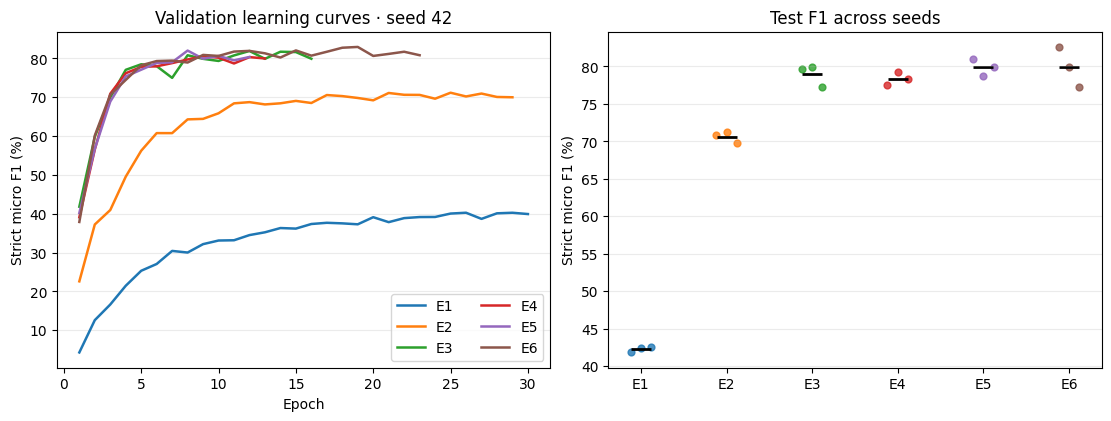

,Train F1 (%),Validation F1 (%),Test BIO repairs,Test window conflicts,Best epoch
experiment,,,,,
E1,46.76,40.41,597.67,0.33,27.00
E2,99.18,70.20,167.00,3.67,25.67
E3,97.23,81.58,65.67,2.67,10.33
E4,98.05,81.13,72.00,0.00,10.33
E5,97.41,81.67,58.67,3.67,8.33
E6,97.46,81.59,54.33,1.33,12.00


In [16]:
display(Markdown("### Validation curves and seed-level variation"))
fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.1), layout="constrained")
first_seed = str(recorded["seeds"][0])
colors = plt.colormaps["tab10"].colors
for i, (exp, epochs) in enumerate(recorded["curves"].items()):
    curve = epochs[first_seed]
    axes[0].plot([row["epoch"] for row in curve], [100 * row["validation_f1"] for row in curve],
                 label=exp, color=colors[i], linewidth=1.8)
    group = runs.loc[runs["experiment"] == exp, "micro_f1"]
    offsets = np.linspace(-0.12, 0.12, len(group))
    axes[1].scatter(i + offsets, 100 * group, color=colors[i], alpha=0.8, s=24)
    axes[1].scatter(i, 100 * group.mean(), marker="_", s=220, linewidth=2, color="black")
axes[0].set(xlabel="Epoch", ylabel="Strict micro F1 (%)", title=f"Validation learning curves · seed {first_seed}")
axes[0].legend(ncol=2)
axes[1].set(xticks=range(len(summary)), xticklabels=list(summary), ylabel="Strict micro F1 (%)",
            title="Test F1 across seeds")
for ax in axes:
    ax.grid(axis="y", alpha=0.25)
plt.show()

diagnostic = runs.groupby("experiment", sort=False)[
    ["training_f1", "validation_f1", "illegal_bio", "overlap_conflicts", "best_epoch"]
].mean()
diagnostic[["training_f1", "validation_f1"]] *= 100
display(diagnostic.rename(columns={"training_f1": "Train F1 (%)", "validation_f1": "Validation F1 (%)",
                                   "illegal_bio": "Test BIO repairs", "overlap_conflicts": "Test window conflicts",
                                   "best_epoch": "Best epoch"}).round(2))

In [17]:
display(Markdown("### Performance by mention type"))
labels = list(recorded["per_type"]["E3"][first_seed])
type_scores = pd.DataFrame(
    {exp: {label: 100 * np.mean([item[label]["f1"] for item in values.values()]) for label in labels}
     for exp, values in recorded["per_type"].items()}
)
type_scores.insert(0, "Test support", [recorded["per_type"]["E3"][first_seed][k]["support"] for k in type_scores.index])
display(type_scores.round(2))

focus = max(("E4", "E5", "E6"), key=lambda exp: summary[exp]["validation_f1"]["mean"])
display(Markdown(f"**Type confusion on exact-span matches.** The adapted model shown is {focus}, "
                 "selected for display by mean validation F1. Values average the raw counts across seeds."))
for exp in ("E3", focus):
    matrix = sum(pd.DataFrame.from_dict(item, orient="index")
                 for item in recorded["confusions"][exp].values()) / len(recorded["seeds"])
    display(Markdown(f"**{exp}** · rows are gold types, columns are predicted types"))
    display(matrix.round(1))
if recorded["examples"]:
    display(Markdown(f"**Illustrative E3 errors from seed {first_seed}.** "
                     "The first available example of each error category is shown."))
    display(pd.DataFrame(recorded["examples"]).set_index("Error"))

### Performance by mention type

,Test support,E1,E2,E3,E4,E5,E6
SpecificDisease,555,49.21,73.31,79.69,79.08,80.34,81.09
DiseaseClass,121,16.60,48.56,58.86,57.47,62.01,57.58
CompositeMention,20,3.05,29.07,57.93,58.36,59.88,50.98
Modifier,264,44.24,81.41,90.81,90.28,90.07,91.54


**Type confusion on exact-span matches.** The adapted model shown is E5, selected for display by mean validation F1. Values average the raw counts across seeds.

**E3** · rows are gold types, columns are predicted types

,SpecificDisease,DiseaseClass,CompositeMention,Modifier
SpecificDisease,446.7,30.0,0.7,3.0
DiseaseClass,8.7,93.3,0.0,0.0
CompositeMention,0.0,0.3,12.7,0.0
Modifier,3.0,1.7,0.0,247.3


**E5** · rows are gold types, columns are predicted types

,SpecificDisease,DiseaseClass,CompositeMention,Modifier
SpecificDisease,454.0,26.3,0.0,3.0
DiseaseClass,9.0,90.7,0.0,0.7
CompositeMention,0.0,0.0,12.7,0.0
Modifier,2.7,1.7,0.0,249.3


**Illustrative E3 errors from seed 42.** The first available example of each error category is shown.

,PMID,Gold mention,Gold type,Predicted mention,Predicted type
Error,,,,,
Boundary error,9949209,copper overload,SpecificDisease,copper overload disease,SpecificDisease
Type error,9634518,hyperphenylalaninemia,SpecificDisease,hyperphenylalaninemia,DiseaseClass
Missed entity,9931324,displaced pupils,SpecificDisease,,


In [18]:
display(Markdown("## 8. Findings and limitations"))
fmt = lambda exp, key: 100 * summary[exp][key]["mean"]
reference = fmt("E3", "micro_f1")
adapted = ("E4", "E5", "E6")
treatment = [f"{exp} {fmt(exp, 'delta_vs_e3'):+.2f} pp" for exp in adapted]
positive = [exp for exp in adapted if recorded["paired_bootstrap_95"][exp][0] > 0]
negative = [exp for exp in adapted if recorded["paired_bootstrap_95"][exp][1] < 0]
uncertain = [exp for exp in adapted if exp not in positive + negative]
interval_readout = []
if positive:
    interval_readout.append(f"The document interval is above zero for {', '.join(positive)}.")
if negative:
    interval_readout.append(f"The document interval is below zero for {', '.join(negative)}.")
if uncertain:
    interval_readout.append(f"The interval includes zero for {', '.join(uncertain)}.")
mlm_seconds = [summary[exp]["mlm_optimization_seconds"]["mean"] for exp in adapted]
e2_params = summary["E2"]["trainable_parameters"]["mean"]
e3_params = summary["E3"]["trainable_parameters"]["mean"]
display(Markdown(
    f"- **Scope of fine-tuning.** E1, E2 and E3 achieved {fmt('E1', 'micro_f1'):.2f}%, "
    f"{fmt('E2', 'micro_f1'):.2f}% and {reference:.2f}% strict test micro F1. "
    "The cost table shows the parameter and GPU-time trade-off. The selected-epoch train–validation "
    "gap is a descriptive indicator of overfitting on this split.\n"
    f"- **Task adaptation.** Paired mean changes versus E3 were {', '.join(treatment)}. "
    "Interpret those changes with the seed variability and paired document intervals. "
    "The adapted runs also incur extra MLM computation.\n"
    f"- **Error analysis.** E3 reached {fmt('E3', 'span_f1'):.2f}% span-only F1 versus "
    f"{reference:.2f}% typed F1. The difference quantifies the effect of the type requirement "
    "among otherwise exact boundaries. Test support varies substantially across mention types, "
    "which makes rare-class estimates especially sensitive to individual examples.\n"
    "- **Scope.** These are held-out results on one biomedical abstract corpus. The study does "
    "not evaluate clinical notes or cross-corpus transfer. E6 combines entity-informed sampling and "
    "span masking. A length-matched random-span control would isolate the annotation contribution. "
    "The small learning-rate search and three seeds leave uncertainty about the ordering of close results."
))

## 8. Findings and limitations

- **Scope of fine-tuning.** E1, E2 and E3 achieved 42.27%, 70.62% and 78.93% strict test micro F1. The cost table shows the parameter and GPU-time trade-off. The selected-epoch train–validation gap is a descriptive indicator of overfitting on this split.
- **Task adaptation.** Paired mean changes versus E3 were E4 -0.59 pp, E5 +0.94 pp, E6 +0.97 pp. Interpret those changes with the seed variability and paired document intervals. The adapted runs also incur extra MLM computation.
- **Error analysis.** E3 reached 83.60% span-only F1 versus 78.93% typed F1. The difference quantifies the effect of the type requirement among otherwise exact boundaries. Test support varies substantially across mention types, which makes rare-class estimates especially sensitive to individual examples.
- **Scope.** These are held-out results on one biomedical abstract corpus. The study does not evaluate clinical notes or cross-corpus transfer. E6 combines entity-informed sampling and span masking. A length-matched random-span control would isolate the annotation contribution. The small learning-rate search and three seeds leave uncertainty about the ordering of close results.